# NLP Group Assignment 2025/26  
## Who Wants to Be a PoliMillionaire? Chatbot

### Group members
- Hedieh Raeisi — hedieh.raeisi@mail.polimi.it
- Ghazal Sepehrirad — Ghazal.sepehrirad@mail.polimi.it
- Amin Sakhaei — amin.sakhaei@mail.polimi.it
- Amirhossein Sharifisadr — amirhossein.sharifisadr@mail.polimi.it

### Coding assistant statement
We used coding assistants to support debugging and making the notebook better.  
The final implementation, experiments, and analysis were done and reviewed by group members.

###Video Linke : https://drive.google.com/file/d/1bc3AZTQ2ZKWZBqGYMKiSXBdV_oviNDIR/view?usp=sharing

## 1. Introduction

The goal of this notebook is to evaluate the **speech interface** of *Who Wants to Be a PoliMillionaire?*.

The speech system has two stages:

1. transcribe the spoken question and spoken answer options with a local ASR model;
2. answer the resulting multiple-choice question with a local open-weight language model.

This makes the speech task harder than the text task because errors can come from either transcription or answer selection. The notebook compares text mode with speech mode, benchmarks Whisper ASR sizes, and adds diagnostics for transcription quality, timing, and speech-specific failure cases.


In [ ]:
#initializing related files from tutorial of the class
from google.colab import drive
import sys
import os
drive.mount('/content/gdrive')



client_package_dir = "/content/gdrive/MyDrive/Colab Notebooks/NLP/millionaire_client"

package_parent_dir = os.path.dirname(client_package_dir)

if package_parent_dir not in sys.path:
    sys.path.append(package_parent_dir)

print("Client package directory:")
print(client_package_dir)

print("\nPackage parent directory added to sys.path:")
print(package_parent_dir)

print("\nFiles inside client package:")
print(os.listdir(client_package_dir))

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Client package directory:
/content/gdrive/MyDrive/Colab Notebooks/NLP/millionaire_client

Package parent directory added to sys.path:
/content/gdrive/MyDrive/Colab Notebooks/NLP

Files inside client package:
['base.py', 'models.py', 'game.py', 'client.py', 'leaderboard.py', 'exceptions.py', 'competitions.py', '__init__.py', 'auth.py', '__pycache__']


In [ ]:
import shutil
import importlib

source_package_dir = "/content/gdrive/MyDrive/Colab Notebooks/NLP/millionaire_client"
target_package_dir = "/content/millionaire_client"

if os.path.exists(target_package_dir):
    shutil.rmtree(target_package_dir)

shutil.copytree(source_package_dir, target_package_dir)


if "/content" not in sys.path:
    sys.path.insert(0, "/content")

importlib.invalidate_caches()

print("Copied package to:", target_package_dir)
print("Files inside local package:")
print(os.listdir(target_package_dir))
print("sys.path first items:")
print(sys.path[:5])

Copied package to: /content/millionaire_client
Files inside local package:
['client.py', '__pycache__', 'competitions.py', 'auth.py', 'game.py', 'base.py', 'leaderboard.py', 'models.py', 'exceptions.py', '__init__.py']
sys.path first items:
['/content', '/env/python', '/usr/lib/python312.zip', '/usr/lib/python3.12', '/usr/lib/python3.12/lib-dynload']


In [ ]:
import subprocess
import sys

# Speech and local-model dependencies with explicit versions
#this part done because colab crashed due to some different dependencies
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "--upgrade",
    "transformers==4.53.2",
    "huggingface_hub==0.33.4",
    "accelerate==1.6.0",
    "sentencepiece",
    "faster-whisper",
    "soundfile",
    "jiwer",
    "pandas",
    "safetensors>=0.5.3",
])

print("Dependencies installed. Restart the Colab runtime if any package was changed.")


Dependencies installed. Restart the Colab runtime if any package was changed.


In [ ]:
import json
import time
import re
import tempfile

import pandas as pd
from faster_whisper import WhisperModel
from millionaire_client import MillionaireClient


In [ ]:
import os
#handeling API with my own user and password
API_URL = "http://131.175.15.22:51111/"
username = os.environ.get("MILLIONAIRE_USERNAME") or input("Millionaire username: ")
password = os.environ.get("MILLIONAIRE_PASSWORD") or __import__("getpass").getpass("Millionaire password: ")

client = MillionaireClient(API_URL)

try:
    user = client.login(username, password)
    print(f"Welcome, {user.username}! Role: {user.role}")
except Exception as e:
    print(f"Login failed: {e}")



Welcome, <user>! Role: student


In [ ]:
#checking different competitions
competitions = client.competitions.list_all()

for comp in competitions:
    print(f"ID: {comp.id} | Name: {comp.name} | Questions: {comp.question_count}")

ID: 0 | Name: Entertainment | Questions: 840
ID: 1 | Name: Ancient History and Politics | Questions: 454
ID: 2 | Name: Science and Nature | Questions: 5347
ID: 3 | Name: Maths | Questions: 390
ID: 4 | Name: Philosophy and Psychology | Questions: 3248
ID: 5 | Name: News | Questions: 1860


In [ ]:
COMPETITION_ID = 2

In [ ]:
#load one model for testing -> here we used flan
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch


def load_answer_model(model_name="google/flan-t5-base"):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)
    model.eval()

    return tokenizer, model, device, model_name


tokenizer, model, device, answer_model_name = load_answer_model("google/flan-t5-base")
print("Loaded answer model:", answer_model_name)


tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Loaded answer model: google/flan-t5-base


In [ ]:
#just a normal prompt for testing
def build_prompt(question_text, option_texts):
    labels = ["A", "B", "C", "D"]


    options_block = "\n".join(
        [f"{labels[i]}. {option_texts[i]}" for i in range(len(option_texts))]
    )

    prompt = f"""
You are playing Who Wants to Be a Millionaire.
Choose the single best answer.

Question:
{question_text}

Options:
{options_block}

Reply only with A, B, C, or D.
"""
    return prompt

In [ ]:
def local_llm_answer(question_text, option_texts):
    prompt = build_prompt(question_text, option_texts)
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
    ).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=10,
        )

    raw_output = tokenizer.decode(outputs[0], skip_special_tokens=True)
    chosen_letter = extract_answer_letter(raw_output) if "extract_answer_letter" in globals() else None

    if chosen_letter is None:
        match = re.search(r"\b[A-D]\b", raw_output.upper())
        chosen_letter = match.group(0) if match else "A"

    return chosen_letter, raw_output


In [ ]:
#play one game to see everything works correctly
def play_text_game(competition_id, max_questions=15):
    game = client.game.start(competition_id=competition_id, mode="text")

    labels = ["A", "B", "C", "D"]
    logs = []

    while game.in_progress and len(logs) < max_questions:
        start_time = time.time()

        question = game.current_question
        question_text = question.text
        option_texts = [opt.text for opt in question.options]

        chosen_letter, raw_model_output = local_llm_answer(question_text, option_texts)

        chosen_index = labels.index(chosen_letter)
        chosen_option_id = question.options[chosen_index].id

        result = game.answer(chosen_option_id)

        elapsed = time.time() - start_time

        logs.append({
            "mode": "text",
            "level": question.level,
            "question": question_text,
            "options": option_texts,
            "model_output": raw_model_output,
            "chosen_letter": chosen_letter,
            "chosen_option_id": chosen_option_id,
            "correct": result.correct,
            "elapsed_seconds": elapsed,
            "earned_amount": result.earned_amount
        })

        print(f"Level {question.level}")
        print("Question:", question_text)
        print("Options:", option_texts)
        print("Model output:", raw_model_output)
        print("Chosen:", chosen_letter)
        print("Correct:", result.correct)
        print("Time:", round(elapsed, 2), "seconds")
        print("-" * 60)

        if result.game_over:
            break

    return pd.DataFrame(logs)

In [ ]:
text_results = play_text_game(COMPETITION_ID)
text_results

Level 0
Question: On a warm sunny afternoon, ocean water splashed onto a rock. A short time later, the rock was dry. Which statement best explains what happened to the water on the rock?
Options: ['Heat melted the water and it disappeared.', 'Salt caused the water to become a gas.', 'Heat caused the water to become a gas.', 'Salt melted the water and it disappeared.']
Model output: A
Chosen: A
Correct: False
Time: 1.11 seconds
------------------------------------------------------------


,mode,level,question,options,model_output,chosen_letter,chosen_option_id,correct,elapsed_seconds,earned_amount
0,text,0,"On a warm sunny afternoon, ocean water splashe...","[Heat melted the water and it disappeared., Sa...",A,A,0,False,1.112003,0


In [ ]:

asr_model = WhisperModel(
    "base.en",
    device="cuda",
    compute_type="float16"
)

tokenizer.json: 0.00B [00:00, ?B/s]

vocabulary.txt: 0.00B [00:00, ?B/s]

model.bin:   0%|          | 0.00/145M [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

In [ ]:
# The API provides the audio as bytes, so we temporarily save it before transcription.
def transcribe_wav_bytes_with_metadata(audio_bytes):
    start_time = time.time()

    with tempfile.NamedTemporaryFile(suffix=".wav", delete=True) as f:
        f.write(audio_bytes)
        f.flush()

        segments, info = asr_model.transcribe(
            f.name,
            beam_size=3,
            language="en",
        )

        segments = list(segments)

    text = " ".join([segment.text.strip() for segment in segments]).strip()
    elapsed_seconds = time.time() - start_time

    avg_logprobs = [
        getattr(segment, "avg_logprob", None)
        for segment in segments
        if getattr(segment, "avg_logprob", None) is not None
    ]
    no_speech_probs = [
        getattr(segment, "no_speech_prob", None)
        for segment in segments
        if getattr(segment, "no_speech_prob", None) is not None
    ]

    return {
        "text": text,
        "asr_elapsed_seconds": elapsed_seconds,
        "asr_segment_count": len(segments),
        "asr_avg_logprob": sum(avg_logprobs) / len(avg_logprobs) if avg_logprobs else None,
        "asr_max_no_speech_prob": max(no_speech_probs) if no_speech_probs else None,
        "detected_language": getattr(info, "language", None),
        "audio_duration": getattr(info, "duration", None),
    }


def transcribe_wav_bytes(audio_bytes):
    return transcribe_wav_bytes_with_metadata(audio_bytes)["text"]


In [ ]:
# Fetch and transcribe one example speech question and its answer options.
game = client.game.start(competition_id=COMPETITION_ID, mode="speech")

In [ ]:
# Start a speech-mode game for a manual transcription check.
game = client.game.start(competition_id=COMPETITION_ID, mode="speech")

# Fetch the spoken question audio and transcribe it.
question_audio = game.fetch_audio_question()
question_text = transcribe_wav_bytes(question_audio)

option_texts = []

for i in range(4):
   # Fetch each spoken answer option in order and transcribe it.
    option_audio = game.fetch_audio_option_next()
    option_text = transcribe_wav_bytes(option_audio)
    option_texts.append(option_text)

print("Question:", question_text)
print("Options:", option_texts)

Question: Sophia put a bad house in a tree in her yard. The bats ate mosquitoes in Sophia's yard at night and roosted in the house during the day. Droppings from the bad house nourish the tree. What kind of relationship exists between Sophia, the bats and the tree?
Options: ['Option A, the relationship is cooperative.', 'Option B, the relationship is parasitic.', 'Option C, the relationship is predatory.', 'Tops and D, the relationship is competitive.']


In [ ]:
def play_speech_game(competition_id, max_questions=15, asr_model_name="base.en", answer_model_name="flan_t5"):
    game = client.game.start(competition_id=competition_id, mode="speech")

    labels = ["A", "B", "C", "D"]
    logs = []

    while game.in_progress and len(logs) < max_questions:
        total_start_time = time.time()

        question_state = game.current_question
        reference_question_text = getattr(question_state, "text", None)
        reference_option_texts = [
            getattr(option, "text", None)
            for option in getattr(question_state, "options", [])
        ]

        question_audio = game.fetch_audio_question()
        question_asr = transcribe_wav_bytes_with_metadata(question_audio)
        question_text = question_asr["text"]

        option_texts = []
        option_asr_metadata = []

        for _ in range(4):
            option_audio = game.fetch_audio_option_next()
            option_asr = transcribe_wav_bytes_with_metadata(option_audio)
            option_texts.append(option_asr["text"])
            option_asr_metadata.append(option_asr)

        answer_start_time = time.time()
        chosen_letter, raw_model_output = local_llm_answer(question_text, option_texts)
        answer_elapsed_seconds = time.time() - answer_start_time

        chosen_index = labels.index(chosen_letter)
        chosen_option_id = game.current_question.options[chosen_index].id

        result = game.answer(chosen_option_id)
        total_elapsed_seconds = time.time() - total_start_time

        logs.append({
            "mode": "speech",
            "asr_model": asr_model_name,
            "answer_model": answer_model_name,
            "level": question_state.level if question_state else None,
            "question_reference": reference_question_text,
            "options_reference": json.dumps(reference_option_texts),
            "question_transcript": question_text,
            "options_transcript": json.dumps(option_texts),
            "question_asr_avg_logprob": question_asr["asr_avg_logprob"],
            "question_asr_max_no_speech_prob": question_asr["asr_max_no_speech_prob"],
            "question_asr_elapsed_seconds": question_asr["asr_elapsed_seconds"],
            "option_asr_metadata": json.dumps(option_asr_metadata),
            "model_output": raw_model_output,
            "chosen_letter": chosen_letter,
            "chosen_option_id": chosen_option_id,
            "correct": result.correct,
            "answer_elapsed_seconds": answer_elapsed_seconds,
            "elapsed_seconds": total_elapsed_seconds,
            "under_30_seconds": total_elapsed_seconds < 30,
            "earned_amount": result.earned_amount,
        })

        print("Question transcript:", question_text)
        print("Options transcript:", option_texts)
        print("Model output:", raw_model_output)
        print("Chosen:", chosen_letter)
        print("Correct:", result.correct)
        print("Total time:", round(total_elapsed_seconds, 2), "seconds")
        print("-" * 60)

        if result.game_over:
            break

    return pd.DataFrame(logs)


In [ ]:
speech_results = play_speech_game(COMPETITION_ID)
speech_results

Question transcript: The sun is classified as
Options transcript: ['Option A, a Decomposer.', 'option B', 'Option C, a star!', 'Tops and D, an organism.']
Model output: C
Chosen: C
Correct: True
Total time: 6.8 seconds
------------------------------------------------------------
Question transcript: Two characteristics of the Nevada climate are low humidity and abundant sunshine. This combination of characteristics most likely results in
Options transcript: ['Option A, High Elevation Snowfall.', 'Option B. Frequent Thunderstorms.', 'Option C, low altitude fog.', 'Tops and D, rapid evaporation.']
Model output: B
Chosen: B
Correct: False
Total time: 8.47 seconds
------------------------------------------------------------


,mode,asr_model,answer_model,level,question_reference,options_reference,question_transcript,options_transcript,question_asr_avg_logprob,question_asr_max_no_speech_prob,question_asr_elapsed_seconds,option_asr_metadata,model_output,chosen_letter,chosen_option_id,correct,answer_elapsed_seconds,elapsed_seconds,under_30_seconds,earned_amount
0,speech,base.en,flan_t5,0,None,"[null, null, null, null]",The sun is classified as,"[""Option A, a Decomposer."", ""option B"", ""Optio...",-0.397217,0.001487,0.738070,"[{""text"": ""Option A, a Decomposer."", ""asr_elap...",C,C,2,True,0.089619,6.799991,True,100
1,speech,base.en,flan_t5,0,None,"[null, null, null, null]",Two characteristics of the Nevada climate are ...,"[""Option A, High Elevation Snowfall."", ""Option...",-0.197115,0.001665,1.136185,"[{""text"": ""Option A, High Elevation Snowfall.""...",B,B,1,False,0.225894,8.468028,True,100


In [ ]:
text_results.to_csv("text_results.csv", index=False)
speech_results.to_csv("speech_results.csv", index=False)

In [ ]:
combined_results = pd.concat([text_results, speech_results], ignore_index=True)

summary = combined_results.groupby("mode").agg(
    questions_answered=("correct", "count"),
    correct_answers=("correct", "sum"),
    average_time=("elapsed_seconds", "mean"),
    max_time=("elapsed_seconds", "max")
)
summary["game_accuracy_out_of_15"] = summary["correct_answers"] / 15

summary

,questions_answered,correct_answers,average_time,max_time,game_accuracy_out_of_15
mode,,,,,
speech,2,1,7.634010,8.468028,0.066667
text,1,0,1.112003,1.112003,0.000000


In [ ]:
def load_asr_model(model_name):
    device = "cuda" if __import__("torch").cuda.is_available() else "cpu"
    compute_type = "float16" if device == "cuda" else "int8"

    return WhisperModel(
        model_name,
        device=device,
        compute_type=compute_type,
    )


In [ ]:
RUN_ASR_COMPARISON = True

if RUN_ASR_COMPARISON:
    asr_model = load_asr_model("tiny.en")
    speech_results_tiny = play_speech_game(COMPETITION_ID, asr_model_name="tiny.en")

    asr_model = load_asr_model("base.en")
    speech_results_base = play_speech_game(COMPETITION_ID, asr_model_name="base.en")

    asr_model = load_asr_model("small.en")
    speech_results_small = play_speech_game(COMPETITION_ID, asr_model_name="small.en")
else:
    print("ASR comparison is disabled. Set RUN_ASR_COMPARISON = True when ready.")


tokenizer.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocabulary.txt: 0.00B [00:00, ?B/s]

model.bin:   0%|          | 0.00/75.5M [00:00<?, ?B/s]

Question transcript: How does the appearance of a constellation change during the night?
Options transcript: ['Option A is distance to the North Star decreases.', "Option B. It's shape appears to become longer.", "Option C. It's brightest stars begin to appear orange.", "Thompson D, it's position, appears to shift relative to the horizon."]
Model output: B
Chosen: B
Correct: False
Total time: 4.93 seconds
------------------------------------------------------------
Question transcript: Scientists are studying a pond. Which property can the scientists measure to understand the amount of energy held by the lake water?
Options transcript: ['Option A, the volume of the lake.', 'Option B, the temperature of the water...', 'Option C, the depth of the lake.', 'Tops and D, the color of the water.']
Model output: B
Chosen: B
Correct: True
Total time: 5.04 seconds
------------------------------------------------------------
Question transcript: Which of the following best explains why the tecton

config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.bin:   0%|          | 0.00/484M [00:00<?, ?B/s]

vocabulary.txt: 0.00B [00:00, ?B/s]

Question transcript: A certain snake species in an ecosystem eats small rodents. If a bird species is introduced into the ecosystem that also eats small rodents, which of these will most likely increase?
Options transcript: ['Option A, competition.', 'Option B! Hahaha! Migration!', 'Option C, mutualism.', 'option d paris tism']
Model output: A
Chosen: A
Correct: True
Total time: 5.05 seconds
------------------------------------------------------------
Question transcript: One process in the formation of sedimentary rocks is when rocks are- Hahaha
Options transcript: ['Option A. Compressed by moving plates.', 'option B broken up and deposited in layers', 'Option C, moved up along fault planes.', 'Option D. Heated and subjected to high pressure.']
Model output: B
Chosen: B
Correct: True
Total time: 5.39 seconds
------------------------------------------------------------
Question transcript: A short plant with a thick, fleshy stem, extensive roots, and a short blooming period would most 

In [ ]:
MAX_GAME_QUESTIONS = 15
if all(name in globals() for name in ["speech_results_tiny", "speech_results_base", "speech_results_small"]):
    speech_results_tiny["asr_model"] = "tiny.en"
    speech_results_base["asr_model"] = "base.en"
    speech_results_small["asr_model"] = "small.en"

    asr_comparison = pd.concat([
        speech_results_tiny,
        speech_results_base,
        speech_results_small,
    ])

    asr_summary = asr_comparison.groupby("asr_model").agg(
        questions_answered=("correct", "count"),
        correct_answers=("correct", "sum"),
        average_time=("elapsed_seconds", "mean"),
        max_time=("elapsed_seconds", "max"),
        under_30_seconds_rate=("under_30_seconds", "mean"),
        average_question_asr_time=("question_asr_elapsed_seconds", "mean"),
        average_question_asr_logprob=("question_asr_avg_logprob", "mean"),
    )
    asr_summary["game_accuracy_out_of_15"] = asr_summary["correct_answers"] / MAX_GAME_QUESTIONS
else:
    asr_summary = pd.DataFrame()
    print("Run the optional ASR comparison first.")

asr_summary

,questions_answered,correct_answers,average_time,max_time,under_30_seconds_rate,average_question_asr_time,average_question_asr_logprob,game_accuracy_out_of_15
asr_model,,,,,,,,
base.en,3,2,4.751707,5.039983,1.0,0.557762,-0.263093,0.133333
small.en,3,2,5.103917,5.394324,1.0,0.646476,-0.262380,0.133333
tiny.en,1,0,4.932286,4.932286,1.0,0.469208,-0.258854,0.000000


In [ ]:
RUN_LARGE_ANSWER_MODEL = True

if RUN_LARGE_ANSWER_MODEL:
    tokenizer, model, device, answer_model_name = load_answer_model("google/flan-t5-large")
    print("Loaded larger answer model:", answer_model_name)
else:
    print("Keeping current answer model:", answer_model_name)


tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.13G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Loaded larger answer model: google/flan-t5-large


In [ ]:
question_text = "What is the capital of France?"
option_texts = ["Berlin", "Madrid", "Paris", "Rome"]

letter, raw = local_llm_answer(question_text, option_texts)

print("Raw output:", raw)
print("Chosen letter:", letter)

Raw output: C
Chosen letter: C


We use `AutoModelForSeq2SeqLM` instead of the Hugging Face pipeline so the same answer function can work with either `google/flan-t5-base` or `google/flan-t5-large`.

The larger model is optional because speech mode already spends extra time on ASR, so the best system must balance answer quality with the 30-second timeout.


In [ ]:
def extract_answer_letter(raw_output):
    raw_output = raw_output.upper()

    # First search for direct answer of A-D
    match = re.search(r"\b[A-D]\b", raw_output)
    if match:
        return match.group(0)

    # check the common option patterns
    if "OPTION A" in raw_output:
        return "A"
    if "OPTION B" in raw_output:
        return "B"
    if "OPTION C" in raw_output:
        return "C"
    if "OPTION D" in raw_output:
        return "D"

    # As a last fallback, choose option A and mark it as a weak prediction in the analysis.
    return "A"

In [ ]:
# Use the previously defined active local_llm_answer function with the currently loaded FLAN-T5 model.
print("Using active answer model:", answer_model_name)


Using active answer model: google/flan-t5-large


## Speech-specific diagnostics

The speech pipeline can fail for different reasons:

- the ASR model transcribes the spoken question incorrectly;
- the ASR model transcribes one or more options incorrectly;
- the answer model receives a good transcript but chooses the wrong option;
- the pipeline is accurate but too slow for the 30-second game limit.

The following cells add diagnostics for these cases.


In [ ]:
def add_speech_diagnostics(df):
    df = df.copy()

    if "question_transcript" in df.columns:
        df["question_transcript_length"] = df["question_transcript"].fillna("").str.split().str.len()
        df["empty_question_transcript"] = df["question_transcript"].fillna("").str.len() == 0

    if "question_asr_avg_logprob" in df.columns:
        df["low_asr_confidence"] = pd.to_numeric(
            df["question_asr_avg_logprob"],
            errors="coerce",
        ) < -1.0

    if "elapsed_seconds" in df.columns:
        df["near_timeout"] = df["elapsed_seconds"] > 25

    if "model_output" in df.columns:
        df["valid_answer_letter"] = df["chosen_letter"].isin(["A", "B", "C", "D"])

    return df


def summarise_speech_pipeline(df):
    df = add_speech_diagnostics(df)

    aggregations = {
        "questions_answered": ("correct", "count"),
        "correct_answers": ("correct", "sum"),
        "average_total_time": ("elapsed_seconds", "mean"),
        "max_total_time": ("elapsed_seconds", "max"),
        "under_30_seconds_rate": ("under_30_seconds", "mean"),
    }

    optional_columns = {
        "average_question_asr_time": ("question_asr_elapsed_seconds", "mean"),
        "average_answer_time": ("answer_elapsed_seconds", "mean"),
        "empty_transcripts": ("empty_question_transcript", "sum"),
        "low_asr_confidence_count": ("low_asr_confidence", "sum"),
        "near_timeout_count": ("near_timeout", "sum"),
    }

    for output_name, aggregation in optional_columns.items():
        if aggregation[0] in df.columns:
            aggregations[output_name] = aggregation

    group_columns = [
        column for column in ["mode", "asr_model", "answer_model"]
        if column in df.columns
    ]

    if not group_columns:
        group_columns = ["mode"]

    summary = df.groupby(group_columns).agg(**aggregations).reset_index()
    summary["game_accuracy_out_of_15"] = summary["correct_answers"] / MAX_GAME_QUESTIONS
    return summary


In [ ]:
if "speech_results" in globals():
    speech_results_diagnostic = add_speech_diagnostics(speech_results)
    speech_pipeline_summary = summarise_speech_pipeline(speech_results_diagnostic)
else:
    speech_results_diagnostic = pd.DataFrame()
    speech_pipeline_summary = pd.DataFrame()
    print("Run the speech game first.")

speech_pipeline_summary


,mode,asr_model,answer_model,questions_answered,correct_answers,average_total_time,max_total_time,under_30_seconds_rate,average_question_asr_time,average_answer_time,empty_transcripts,low_asr_confidence_count,near_timeout_count,game_accuracy_out_of_15
0,speech,base.en,flan_t5,2,1,7.63401,8.468028,1.0,0.937128,0.157757,0,0,0,0.066667


In [ ]:
if "speech_results_diagnostic" in globals() and len(speech_results_diagnostic) > 0:
    speech_error_cases = speech_results_diagnostic[
        speech_results_diagnostic["correct"] == False
    ].copy()

    speech_error_columns = [
        "asr_model",
        "level",
        "question_transcript",
        "options_transcript",
        "question_asr_avg_logprob",
        "model_output",
        "chosen_letter",
        "elapsed_seconds",
        "low_asr_confidence",
        "near_timeout",
    ]
    speech_error_columns = [
        column for column in speech_error_columns
        if column in speech_error_cases.columns
    ]

    speech_error_cases[speech_error_columns]
else:
    pd.DataFrame()


In [ ]:
try:
    from jiwer import wer
except Exception:
    wer = None


def add_reference_wer_if_available(df):
    df = df.copy()

    if wer is None:
        df["question_wer"] = None
        return df

    if "question_reference" not in df.columns or "question_transcript" not in df.columns:
        df["question_wer"] = None
        return df

    def row_wer(row):
        reference = row.get("question_reference")
        hypothesis = row.get("question_transcript")

        if not isinstance(reference, str) or not reference.strip():
            return None
        if not isinstance(hypothesis, str):
            return None

        return wer(reference, hypothesis)

    df["question_wer"] = df.apply(row_wer, axis=1)
    return df


if "speech_results_diagnostic" in globals() and len(speech_results_diagnostic) > 0:
    speech_results_with_wer = add_reference_wer_if_available(speech_results_diagnostic)
    speech_results_with_wer[
        [
            column for column in [
                "question_reference",
                "question_transcript",
                "question_wer",
                "correct",
            ]
            if column in speech_results_with_wer.columns
        ]
    ].head()
else:
    speech_results_with_wer = pd.DataFrame()
    print("No speech results available for WER analysis.")


## Final speech result story

Use the speech results to explain the full pipeline, not only the final correct-answer count.

Suggested story:

- Text mode gives the baseline for the answer model without transcription errors.
- Speech mode measures the full end-to-end system: ASR plus answer selection.
- If speech performance is lower than text performance, inspect the wrong cases to separate ASR errors from reasoning errors.
- Compare Whisper `tiny.en`, `base.en`, and `small.en` by correct answers out of 15, speed, and under-30-second rate.
- The best speech system is not necessarily the largest ASR model; it must answer enough questions correctly while still staying below the timeout.
- Report examples where the transcription changed the meaning of the question or options.

In [ ]:
available_speech_tables = []

if "summary" in globals() and isinstance(summary, pd.DataFrame):
    available_speech_tables.append(summary.reset_index())

if "speech_pipeline_summary" in globals() and len(speech_pipeline_summary) > 0:
    available_speech_tables.append(speech_pipeline_summary)

if "asr_summary" in globals() and len(asr_summary) > 0:
    available_speech_tables.append(asr_summary.reset_index())

if available_speech_tables:
    final_speech_summary = pd.concat(
        available_speech_tables,
        ignore_index=True,
        sort=False,
    )
else:
    final_speech_summary = pd.DataFrame()

final_speech_summary.to_csv("speech_final_summary.csv", index=False)

if "speech_results_diagnostic" in globals() and len(speech_results_diagnostic) > 0:
    speech_results_diagnostic.to_csv("speech_question_level_diagnostics.csv", index=False)

if "speech_error_cases" in globals() and len(speech_error_cases) > 0:
    speech_error_cases.to_csv("speech_error_cases.csv", index=False)

final_speech_summary


,mode,questions_answered,correct_answers,average_time,max_time,game_accuracy_out_of_15,asr_model,answer_model,average_total_time,max_total_time,under_30_seconds_rate,average_question_asr_time,average_answer_time,empty_transcripts,low_asr_confidence_count,near_timeout_count,average_question_asr_logprob
0,speech,2,1,7.634010,8.468028,0.066667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,text,1,0,1.112003,1.112003,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,speech,2,1,NaN,NaN,0.066667,base.en,flan_t5,7.63401,8.468028,1.0,0.937128,0.157757,0.0,0.0,0.0,NaN
3,NaN,3,2,4.751707,5.039983,0.133333,base.en,NaN,NaN,NaN,1.0,0.557762,NaN,NaN,NaN,NaN,-0.263093
4,NaN,3,2,5.103917,5.394324,0.133333,small.en,NaN,NaN,NaN,1.0,0.646476,NaN,NaN,NaN,NaN,-0.262380
5,NaN,1,0,4.932286,4.932286,0.000000,tiny.en,NaN,NaN,NaN,1.0,0.469208,NaN,NaN,NaN,NaN,-0.258854



## 2. Enhanced speech experiments matching the text notebook

This section mirrors the extra work from the text notebook for the speech pipeline:

- the same prompt styles: baseline, short science prompt, science expert, elimination, few-shot, and short hidden reasoning;
- repeated prompt benchmarking;
- ASR-size comparison with Whisper `tiny.en`, `base.en`, and `small.en`;
- answer-model comparison across FLAN-T5, Qwen, Phi, DeepSeek, Gemma, and Llama where your Colab/Hugging Face access allows it;
- speech-specific diagnostics, topic/error analysis, final model-comparison tables, optional RAG, and optional prompt ensemble.

The speech task is evaluated end-to-end: audio transcription plus answer selection. For this reason the logs keep ASR time, answer-model time, transcript quality signals, total time, timeout risk, and game performance.


In [ ]:

# This is enhanced speech experiment setup.
# These imports are separate from the first part of the notebook, so this section can be safely rerun.

import gc
import json
import math
import os
import re
import sys
import time
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM

try:
    from IPython.display import display
except Exception:
    display = print

LABELS = ["A", "B", "C", "D"]
MAX_GAME_QUESTIONS = 15
DEFAULT_DELAY_SECONDS = 1.5

# Optional dependencies for later sections.

INSTALL_OPTIONAL_SPEECH_DEPS = True

if INSTALL_OPTIONAL_SPEECH_DEPS:
    import subprocess
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "datasets",
        "bitsandbytes",
        "safetensors>=0.5.3",
    ])
else:
    print("Optional enhanced dependencies are not installed by this cell. Set INSTALL_OPTIONAL_SPEECH_DEPS = True only if needed.")


def clear_memory():
    """Release GPU memory between large answer-model experiments."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


print("Enhanced speech setup ready. CUDA available:", torch.cuda.is_available())


Enhanced speech setup ready. CUDA available: True



### Speech prompt builders

The text notebook tests several prompt formulations. The functions below adapt the same prompt families to speech transcripts, where answers are selected by letters `A` to `D` instead of directly returning option IDs.


In [ ]:

def clean_transcript(text):
    text = "" if text is None else str(text)
    return re.sub(r"\s+", " ", text).strip()


def format_speech_options(option_texts):
    option_texts = list(option_texts or [])[:4]
    option_texts = option_texts + [""] * (4 - len(option_texts))
    return "\n".join(f"{LABELS[i]}. {clean_transcript(option_texts[i])}" for i in range(4))


def build_speech_prompt_baseline(question_text, option_texts, rag_context=None):
    context_block = f"\nUseful context:\n{rag_context}\n" if rag_context else ""
    return f"""
You are playing Who Wants to Be a Millionaire.
Choose the single best answer.{context_block}

Question:
{clean_transcript(question_text)}

Options:
{format_speech_options(option_texts)}

Reply only with A, B, C, or D.
""".strip()


def build_speech_prompt_science_short(question_text, option_texts, rag_context=None):
    context_block = f"\nContext:\n{rag_context}\n" if rag_context else ""
    return f"""
Science and Nature quiz.{context_block}

Question:
{clean_transcript(question_text)}

Options:
{format_speech_options(option_texts)}

Choose the scientifically correct option.
Return only A, B, C, or D.
""".strip()


def build_speech_prompt_science_expert(question_text, option_texts, rag_context=None):
    context_block = f"\nUse this retrieved context if it is relevant:\n{rag_context}\n" if rag_context else ""
    return f"""
You are an expert in science and nature.
Choose the most scientifically accurate answer using biology, chemistry, physics, astronomy, earth science, and general natural science knowledge.{context_block}

Question:
{clean_transcript(question_text)}

Options:
{format_speech_options(option_texts)}

Return only the answer letter. Do not explain.
""".strip()


def build_speech_prompt_elimination(question_text, option_texts, rag_context=None):
    context_block = f"\nRelevant context:\n{rag_context}\n" if rag_context else ""
    return f"""
Answer this Science and Nature multiple-choice question.
Internally eliminate options that are scientifically unlikely.
Do not show your reasoning.{context_block}

Question:
{clean_transcript(question_text)}

Options:
{format_speech_options(option_texts)}

Final answer as one letter only:
""".strip()


def build_speech_prompt_few_shot_science(question_text, option_texts, rag_context=None):
    context_block = f"\nUseful context for the real question:\n{rag_context}\n" if rag_context else ""
    return f"""
You are playing a Science and Nature multiple-choice quiz.
Choose the most scientifically accurate answer.
Return only the answer letter.

Example 1:
Question: Which planet is known as the Red Planet?
Options:
A. Earth
B. Mars
C. Jupiter
D. Venus
Answer: B

Example 2:
Question: What gas do plants absorb during photosynthesis?
Options:
A. Oxygen
B. Nitrogen
C. Carbon dioxide
D. Hydrogen
Answer: C

Example 3:
Question: What is the chemical symbol for gold?
Options:
A. Ag
B. Au
C. Fe
D. Pb
Answer: B
{context_block}

Now answer the real question.

Question:
{clean_transcript(question_text)}

Options:
{format_speech_options(option_texts)}

Answer:
""".strip()


def build_speech_prompt_chain_of_thought(question_text, option_texts, rag_context=None):
    context_block = f"\nUse this context if helpful:\n{rag_context}\n" if rag_context else ""
    return f"""
You are answering a Science and Nature multiple-choice quiz.
Think briefly and silently. Do not reveal the reasoning.
After thinking, finish with exactly this format:
Final answer: <A/B/C/D>{context_block}

Question:
{clean_transcript(question_text)}

Options:
{format_speech_options(option_texts)}

Final answer:
""".strip()


SPEECH_PROMPT_BUILDERS = {
    "baseline": build_speech_prompt_baseline,
    "science_short": build_speech_prompt_science_short,
    "science_expert": build_speech_prompt_science_expert,
    "elimination": build_speech_prompt_elimination,
    "few_shot_science": build_speech_prompt_few_shot_science,
    "chain_of_thought": build_speech_prompt_chain_of_thought,
}

SPEECH_PROMPT_TYPES = [
    "baseline",
    "science_short",
    "science_expert",
    "elimination",
    "few_shot_science",
    "chain_of_thought",
]

FAST_SPEECH_PROMPT_TYPES = [
    "science_short",
    "science_expert",
    "elimination",
]


def build_speech_prompt(question_text, option_texts, prompt_type="science_short", rag_context=None):
    builder = SPEECH_PROMPT_BUILDERS.get(prompt_type, build_speech_prompt_science_short)
    return builder(question_text, option_texts, rag_context=rag_context)

#parser
def parse_answer_letter(raw_output, valid_letters=None):
    valid_letters = list(valid_letters or LABELS)
    valid_set = set(valid_letters)
    text = str(raw_output or "").strip()
    upper_text = text.upper()

    patterns = [
        r"(?:FINAL\s*ANSWER|ANSWER|OPTION|CHOICE)\s*[:\-]?\s*\(?([A-D])\)?",
        r"^\s*\(?([A-D])\)?\s*$",
        r"\b([A-D])\s*[\).:]",
        r"\b([A-D])\b",
    ]

    for pattern in patterns:
        matches = re.findall(pattern, upper_text, flags=re.IGNORECASE | re.MULTILINE)
        for match in reversed(matches):
            letter = str(match).upper()
            if letter in valid_set:
                return letter

    return None


def option_text_to_letter(raw_output, option_texts):
    """Fallback parser: if the model writes the option text instead of a letter, map it back to A-D."""
    raw_norm = clean_transcript(raw_output).lower()
    if not raw_norm:
        return None

    for i, option in enumerate(list(option_texts or [])[:4]):
        option_norm = clean_transcript(option).lower()
        if option_norm and option_norm in raw_norm:
            return LABELS[i]
    return None


print("Speech prompt types:", SPEECH_PROMPT_TYPES)


Speech prompt types: ['baseline', 'science_short', 'science_expert', 'elimination', 'few_shot_science', 'chain_of_thought']


### Reusable answer-model loading and generation

This block is used to load and run the answer models for the speech pipeline. It supports both sequence-to-sequence models, such as FLAN-T5, and chat/causal models, such as Qwen, Phi, DeepSeek, Gemma, and Llama.




In [ ]:
# These variables keep track of the active answer model so it can be reused without reloading each time.
ACTIVE_ANSWER_TOKENIZER = None
ACTIVE_ANSWER_MODEL = None
ACTIVE_ANSWER_MODEL_KIND = None
ACTIVE_ANSWER_MODEL_LABEL = None
ACTIVE_ANSWER_MODEL_ID = None
ACTIVE_ANSWER_DEVICE = None


PHI_MODEL_MARKERS = (
    "phi-3",
    "phi3",
    "phi_3",
    "microsoft/phi",
)


def is_phi_model_id(model_id):
    """Return True for Phi/Phi-3 family models that need safer generation settings."""
    model_id_text = str(model_id or "").lower()
    return any(marker in model_id_text for marker in PHI_MODEL_MARKERS)


def get_model_input_device(model):
    """Find a safe device for input tensors, including models loaded with device_map='auto'."""
    try:
        return next(model.parameters()).device
    except Exception:
        return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def unload_active_answer_model():
    global ACTIVE_ANSWER_TOKENIZER, ACTIVE_ANSWER_MODEL, ACTIVE_ANSWER_MODEL_KIND
    global ACTIVE_ANSWER_MODEL_LABEL, ACTIVE_ANSWER_MODEL_ID, ACTIVE_ANSWER_DEVICE

    ACTIVE_ANSWER_TOKENIZER = None
    ACTIVE_ANSWER_MODEL = None
    ACTIVE_ANSWER_MODEL_KIND = None
    ACTIVE_ANSWER_MODEL_LABEL = None
    ACTIVE_ANSWER_MODEL_ID = None
    ACTIVE_ANSWER_DEVICE = None
    clear_memory()


def load_speech_answer_model(
    model_id,
    model_label=None,
    model_kind="causal",
    use_4bit=False,
    trust_remote_code=None,
):
    """Load one answer model for speech experiments.

    model_kind:
    - "seq2seq" for FLAN-T5-style models;
    - "causal" for chat/instruct models.

    Phi note:
    - Phi-3/Phi-3.5 can fail with a DynamicCache/get_max_length error when the
      downloaded remote modeling code is used with newer Transformers versions.
    - For Phi we therefore prefer the native Transformers implementation
      (`trust_remote_code=False`), force eager attention, and later disable cache
      during generation.
    """
    global ACTIVE_ANSWER_TOKENIZER, ACTIVE_ANSWER_MODEL, ACTIVE_ANSWER_MODEL_KIND
    global ACTIVE_ANSWER_MODEL_LABEL, ACTIVE_ANSWER_MODEL_ID, ACTIVE_ANSWER_DEVICE

    unload_active_answer_model()

    model_label = model_label or model_id.split("/")[-1].replace("-", "_").lower()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = torch.float16 if torch.cuda.is_available() else torch.float32
    is_phi_model = is_phi_model_id(model_id)

    if trust_remote_code is None:
        trust_remote_code = False if is_phi_model else True

    quantization_config = None
    if use_4bit:
        try:
            from transformers import BitsAndBytesConfig
            quantization_config = BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_compute_dtype=torch.float16,
                bnb_4bit_use_double_quant=True,
                bnb_4bit_quant_type="nf4",
            )
        except Exception as exc:
            raise RuntimeError(
                "4-bit loading needs bitsandbytes. Set INSTALL_OPTIONAL_SPEECH_DEPS = True and rerun setup."
            ) from exc

    tokenizer_local = AutoTokenizer.from_pretrained(
        model_id,
        trust_remote_code=trust_remote_code,
    )

    if tokenizer_local.pad_token_id is None and tokenizer_local.eos_token_id is not None:
        tokenizer_local.pad_token = tokenizer_local.eos_token

    # Left padding is safer for decoder-only chat models when batching/generating.
    if model_kind != "seq2seq":
        tokenizer_local.padding_side = "left"

    if model_kind == "seq2seq":
        model_local = AutoModelForSeq2SeqLM.from_pretrained(
            model_id,
            torch_dtype=dtype,
            trust_remote_code=trust_remote_code,
        ).to(device)
    else:
        model_kwargs = {
            "torch_dtype": dtype,
            "trust_remote_code": trust_remote_code,
        }


        if is_phi_model:
            model_kwargs["attn_implementation"] = "eager"

        if torch.cuda.is_available():
            model_kwargs["device_map"] = "auto"
        if quantization_config is not None:
            model_kwargs["quantization_config"] = quantization_config

        model_local = AutoModelForCausalLM.from_pretrained(model_id, **model_kwargs)

        if not torch.cuda.is_available():
            model_local = model_local.to(device)

    if hasattr(model_local, "generation_config"):
        model_local.generation_config.do_sample = False
        if is_phi_model:
            # This avoids the DynamicCache/get_max_length incompatibility seen in the previous run.
            model_local.generation_config.use_cache = False

    model_local.eval()

    ACTIVE_ANSWER_TOKENIZER = tokenizer_local
    ACTIVE_ANSWER_MODEL = model_local
    ACTIVE_ANSWER_MODEL_KIND = model_kind
    ACTIVE_ANSWER_MODEL_LABEL = model_label
    ACTIVE_ANSWER_MODEL_ID = model_id
    ACTIVE_ANSWER_DEVICE = device

    print(
        f"Loaded answer model: {model_label} ({model_id}) | "
        f"kind={model_kind} | device={device} | 4bit={use_4bit} | "
        f"trust_remote_code={trust_remote_code} | phi_safe_mode={is_phi_model}"
    )
    return tokenizer_local, model_local


def format_for_active_chat_model(prompt):
    tokenizer_local = ACTIVE_ANSWER_TOKENIZER
    if tokenizer_local is None:
        raise RuntimeError("Load an answer model first with load_speech_answer_model(...).")

    messages = [
        {
            "role": "system",
            "content": "You are a Science and Nature quiz assistant. Return only one answer letter: A, B, C, or D.",
        },
        {"role": "user", "content": prompt},
    ]

    if getattr(tokenizer_local, "chat_template", None):
        return tokenizer_local.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )

    return "System: " + messages[0]["content"] + "\nUser: " + messages[1]["content"] + "\nAssistant:"


def safe_generate_causal_answer(inputs, token_budget):
    """Generate from the active causal model, with a Phi-specific cache fallback."""
    is_phi_model = is_phi_model_id(ACTIVE_ANSWER_MODEL_ID)

    generation_kwargs = {
        "max_new_tokens": token_budget,
        "do_sample": False,
        "pad_token_id": ACTIVE_ANSWER_TOKENIZER.pad_token_id or ACTIVE_ANSWER_TOKENIZER.eos_token_id,
        "eos_token_id": ACTIVE_ANSWER_TOKENIZER.eos_token_id,
    }

    # Phi fix: disable cache to avoid DynamicCache/get_max_length errors.
    if is_phi_model:
        generation_kwargs["use_cache"] = False
    else:
        generation_kwargs["use_cache"] = True

    try:
        return ACTIVE_ANSWER_MODEL.generate(**inputs, **generation_kwargs)
    except AttributeError as exc:
        message = str(exc)
        if "DynamicCache" in message and "get_max_length" in message:
            print("Phi cache compatibility issue detected; retrying with use_cache=False.")
            generation_kwargs["use_cache"] = False
            if hasattr(ACTIVE_ANSWER_MODEL, "generation_config"):
                ACTIVE_ANSWER_MODEL.generation_config.use_cache = False
            return ACTIVE_ANSWER_MODEL.generate(**inputs, **generation_kwargs)
        raise


def generate_active_speech_answer(
    question_text,
    option_texts,
    prompt_type="science_short",
    rag_context=None,
    max_new_tokens=None,
):
    """Generate an answer from the currently loaded speech answer model."""
    if ACTIVE_ANSWER_MODEL is None or ACTIVE_ANSWER_TOKENIZER is None:
        # Backward compatible fallback, use the original FLAN function if it exists.
        if "local_llm_answer" in globals():
            start_time = time.time()
            chosen_letter, raw_output = local_llm_answer(question_text, option_texts)
            response_time = time.time() - start_time
            parsed = parse_answer_letter(chosen_letter) or parse_answer_letter(raw_output) or option_text_to_letter(raw_output, option_texts)
            return {
                "prompt_type": prompt_type,
                "prompt": build_speech_prompt(question_text, option_texts, prompt_type, rag_context=rag_context),
                "raw_response": raw_output,
                "predicted_letter": parsed,
                "valid_output": parsed in LABELS,
                "response_time": response_time,
                "model_label": globals().get("answer_model_name", "original_flan_t5"),
            }
        raise RuntimeError("No active answer model is loaded and local_llm_answer is not available.")

    prompt = build_speech_prompt(question_text, option_texts, prompt_type=prompt_type, rag_context=rag_context)
    token_budget = max_new_tokens if max_new_tokens is not None else (80 if prompt_type == "chain_of_thought" else 16)

    start_time = time.time()

    if ACTIVE_ANSWER_MODEL_KIND == "seq2seq":
        inputs = ACTIVE_ANSWER_TOKENIZER(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=1024,
        ).to(get_model_input_device(ACTIVE_ANSWER_MODEL))

        with torch.no_grad():
            outputs = ACTIVE_ANSWER_MODEL.generate(
                **inputs,
                max_new_tokens=token_budget,
                do_sample=False,
                pad_token_id=ACTIVE_ANSWER_TOKENIZER.pad_token_id,
            )

        raw_output = ACTIVE_ANSWER_TOKENIZER.decode(outputs[0], skip_special_tokens=True).strip()
    else:
        formatted_prompt = format_for_active_chat_model(prompt)
        inputs = ACTIVE_ANSWER_TOKENIZER(
            formatted_prompt,
            return_tensors="pt",
            truncation=True,
            max_length=2048,
        ).to(get_model_input_device(ACTIVE_ANSWER_MODEL))

        with torch.no_grad():
            outputs = safe_generate_causal_answer(inputs, token_budget)

        generated_ids = outputs[0][inputs["input_ids"].shape[1]:]
        raw_output = ACTIVE_ANSWER_TOKENIZER.decode(generated_ids, skip_special_tokens=True).strip()

    response_time = time.time() - start_time
    parsed = parse_answer_letter(raw_output) or option_text_to_letter(raw_output, option_texts)

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_output,
        "predicted_letter": parsed,
        "valid_output": parsed in LABELS,
        "response_time": response_time,
        "model_label": ACTIVE_ANSWER_MODEL_LABEL,
        "model_id": ACTIVE_ANSWER_MODEL_ID,
    }


# Backward-compatible alias for the benchmark functions below.
def active_speech_answer_fn(question_text, option_texts, prompt_type="science_short"):
    return generate_active_speech_answer(question_text, option_texts, prompt_type=prompt_type)


print("Reusable speech answer model utilities loaded. Phi safe mode is available.")


Reusable speech answer model utilities loaded. Phi safe mode is available.


### Optional Phi smoke test

Test this beacuse my phi crashed

In [ ]:
RUN_PHI_SMOKE_TEST = False

if RUN_PHI_SMOKE_TEST:
    load_speech_answer_model(
        model_id="microsoft/Phi-3.5-mini-instruct",
        model_label="phi_3_5_mini_speech_smoke_test",
        model_kind="causal",
        use_4bit=False,
    )

    phi_test = generate_active_speech_answer(
        question_text="Which gas do plants mainly take in during photosynthesis?",
        option_texts=["Oxygen", "Carbon dioxide", "Nitrogen", "Helium"],
        prompt_type="science_short",
    )

    print(phi_test)
    unload_active_answer_model()
else:
    print("Phi smoke test skipped. Set RUN_PHI_SMOKE_TEST = True to test Phi loading/generation.")


Phi smoke test skipped. Set RUN_PHI_SMOKE_TEST = True to test Phi loading/generation.



### Pluggable speech game loop

This is the speech equivalent of the text notebook’s general game runner. It keeps the ASR stage fixed or variable, then passes the transcripts to any answer function.


In [ ]:
def safe_json_dumps(value):
    try:
        return json.dumps(value, ensure_ascii=False)
    except Exception:
        return json.dumps(str(value), ensure_ascii=False)


def play_speech_game_with_answer_fn(
    competition_id,
    answer_fn,
    prompt_type="science_short",
    system_name="speech_system",
    asr_model_name="base.en",
    max_questions=MAX_GAME_QUESTIONS,
    delay_seconds=DEFAULT_DELAY_SECONDS,
    run_id=1,
):
    """Run one full speech-mode game with a pluggable answer function."""
    game = client.game.start(competition_id=competition_id, mode="speech")

    logs = []
    questions_reached_this_run = 0

    print("Started speech game session:", getattr(game, "session_id", None))
    print("System:", system_name, "| prompt:", prompt_type, "| ASR:", asr_model_name)

    while getattr(game, "in_progress", True) and len(logs) < max_questions:
        total_start_time = time.time()
        question_state = game.current_question

        if question_state is None:
            print("No active speech question.")
            break

        api_level = getattr(game, "current_level", None)
        if api_level is None or api_level == 0:
            api_level = getattr(question_state, "level", None)
        level_before_answer = api_level or (questions_reached_this_run + 1)

        reference_question_text = getattr(question_state, "text", None)
        reference_option_texts = [
            getattr(option, "text", None)
            for option in getattr(question_state, "options", [])
        ]
        option_ids = [getattr(option, "id", None) for option in getattr(question_state, "options", [])]

        question_audio = game.fetch_audio_question()
        question_asr = transcribe_wav_bytes_with_metadata(question_audio)
        question_text = question_asr.get("text", "")

        option_texts = []
        option_asr_metadata = []
        option_asr_elapsed_total = 0.0

        for _ in range(4):
            option_audio = game.fetch_audio_option_next()
            option_asr = transcribe_wav_bytes_with_metadata(option_audio)
            option_texts.append(option_asr.get("text", ""))
            option_asr_metadata.append(option_asr)
            option_asr_elapsed_total += float(option_asr.get("asr_elapsed_seconds") or 0.0)

        prediction = answer_fn(question_text, option_texts, prompt_type=prompt_type)
        predicted_letter = prediction.get("predicted_letter")
        used_fallback = False

        if predicted_letter not in LABELS:
            used_fallback = True
            predicted_letter = "A"

        chosen_index = LABELS.index(predicted_letter)
        if chosen_index >= len(option_ids) or option_ids[chosen_index] is None:
            used_fallback = True
            chosen_index = 0
            predicted_letter = "A"

        chosen_option_id = option_ids[chosen_index]
        result = game.answer(chosen_option_id)
        total_elapsed_seconds = time.time() - total_start_time
        logged_prompt_type = prediction.get("prompt_type", prompt_type)
        questions_reached_this_run += 1

        log_row = {
            "mode": "speech",
            "run_id": run_id,
            "system_name": system_name,
            "model_label": prediction.get("model_label", system_name),
            "model_id": prediction.get("model_id"),
            "asr_model": asr_model_name,
            "prompt_type": logged_prompt_type,
            "level": getattr(question_state, "level", None),
            "level_before_answer": level_before_answer,
            "question_reference": reference_question_text,
            "options_reference": safe_json_dumps(reference_option_texts),
            "question_transcript": question_text,
            "options_transcript": safe_json_dumps(option_texts),
            "question_text": question_text,
            "option_texts": safe_json_dumps(option_texts),
            "prompt": prediction.get("prompt"),
            "raw_response": prediction.get("raw_response"),
            "rag_used": prediction.get("rag_used"),
            "rag_mode": prediction.get("rag_mode"),
            "rag_context": prediction.get("rag_context"),
            "rag_fallback_reason": prediction.get("rag_fallback_reason"),
            "rag_retrieval_score": prediction.get("rag_retrieval_score"),
            "rag_matched_terms": prediction.get("rag_matched_terms"),
            "rag_sources": prediction.get("rag_sources"),
            "rag_retrieved_docs": safe_json_dumps(prediction.get("rag_retrieved_docs", [])),
            "model_output": prediction.get("raw_response"),
            "chosen_letter": predicted_letter,
            "predicted_letter": predicted_letter,
            "valid_output": bool(prediction.get("valid_output", False)),
            "used_fallback": used_fallback,
            "chosen_option_id": chosen_option_id,
            "correct": bool(getattr(result, "correct", False)),
            "response_time": prediction.get("response_time"),
            "answer_elapsed_seconds": prediction.get("response_time"),
            "question_asr_avg_logprob": question_asr.get("asr_avg_logprob"),
            "question_asr_max_no_speech_prob": question_asr.get("asr_max_no_speech_prob"),
            "question_asr_elapsed_seconds": question_asr.get("asr_elapsed_seconds"),
            "option_asr_elapsed_seconds": option_asr_elapsed_total,
            "option_asr_metadata": safe_json_dumps(option_asr_metadata),
            "audio_duration": question_asr.get("audio_duration"),
            "elapsed_seconds": total_elapsed_seconds,
            "under_30_seconds": total_elapsed_seconds < 30,
            "near_timeout": total_elapsed_seconds > 25,
            "earned_amount": getattr(result, "earned_amount", None),
            "game_over": getattr(result, "game_over", False),
        }
        logs.append(log_row)

        print()
        print(f"Level {level_before_answer}")
        print("Question transcript:", question_text)
        print("Options transcript:", option_texts)
        print("Raw response:", prediction.get("raw_response"))
        print("Submitted:", predicted_letter, "| Correct:", getattr(result, "correct", None))
        print("ASR time:", round(float(question_asr.get("asr_elapsed_seconds") or 0.0) + option_asr_elapsed_total, 2), "seconds")
        print("Answer time:", round(float(prediction.get("response_time") or 0.0), 2), "seconds")
        print("Total time:", round(total_elapsed_seconds, 2), "seconds")
        print("-" * 70)

        if getattr(result, "game_over", False):
            break

        if delay_seconds:
            time.sleep(delay_seconds)

    return pd.DataFrame(logs)


def benchmark_speech_answer_fn(
    answer_fn,
    model_label,
    prompt_type="science_short",
    n_runs=3,
    competition_id=COMPETITION_ID,
    asr_model_name="base.en",
    max_questions=MAX_GAME_QUESTIONS,
    delay_seconds=DEFAULT_DELAY_SECONDS,
):
    run_dfs = []
    for run_id in range(1, n_runs + 1):
        print(f"\n=== Speech run {run_id}/{n_runs}: {model_label} | {prompt_type} | {asr_model_name} ===")
        df_run = play_speech_game_with_answer_fn(
            competition_id=competition_id,
            answer_fn=answer_fn,
            prompt_type=prompt_type,
            system_name=model_label,
            asr_model_name=asr_model_name,
            max_questions=max_questions,
            delay_seconds=delay_seconds,
            run_id=run_id,
        )
        df_run["model_label"] = model_label
        run_dfs.append(df_run)

    if not run_dfs:
        return pd.DataFrame()
    return pd.concat(run_dfs, ignore_index=True, sort=False)


def benchmark_speech_prompts(
    answer_fn,
    model_label,
    prompt_types=None,
    n_runs=3,
    competition_id=COMPETITION_ID,
    asr_model_name="base.en",
    max_questions=MAX_GAME_QUESTIONS,
    delay_seconds=DEFAULT_DELAY_SECONDS,
):
    prompt_types = prompt_types or SPEECH_PROMPT_TYPES
    results = []

    for prompt_type in prompt_types:
        df_prompt = benchmark_speech_answer_fn(
            answer_fn=answer_fn,
            model_label=model_label,
            prompt_type=prompt_type,
            n_runs=n_runs,
            competition_id=competition_id,
            asr_model_name=asr_model_name,
            max_questions=max_questions,
            delay_seconds=delay_seconds,
        )
        results.append(df_prompt)

    if not results:
        return pd.DataFrame()
    return pd.concat(results, ignore_index=True, sort=False)



### Shared speech summaries, topic analysis, and error analysis

These functions mirror the text notebook’s summary tables, but add speech-specific failure categories such as low ASR confidence, empty transcripts, and timeout risk.


In [ ]:
def get_speech_run_count(df):
    if df.empty:
        return pd.DataFrame(columns=["model_label", "prompt_type", "asr_model", "runs"])
    group_cols = [c for c in ["model_label", "prompt_type", "asr_model"] if c in df.columns]
    if "run_id" in df.columns:
        return df.groupby(group_cols)["run_id"].nunique().reset_index(name="runs")
    return df.groupby(group_cols).size().reset_index(name="runs")


def make_speech_run_summary(df):
    if df is None or len(df) == 0:
        return pd.DataFrame()

    df = df.copy()
    df["correct"] = df["correct"].astype(bool)

    for flag_column in ["used_fallback", "near_timeout", "under_30_seconds", "valid_output", "rag_used"]:
        if flag_column in df.columns:
            df[flag_column] = df[flag_column].fillna(False).astype(bool)

    if "rag_retrieval_score" in df.columns:
        df["rag_retrieval_score"] = pd.to_numeric(df["rag_retrieval_score"], errors="coerce")

    group_cols = [c for c in ["model_label", "prompt_type", "asr_model", "run_id"] if c in df.columns]
    if not group_cols:
        group_cols = ["mode"]

    aggregations = {
        "questions_reached": ("correct", "count"),
        "correct_answers": ("correct", "sum"),
        "run_question_correct_rate": ("correct", "mean"),
        "final_earned_amount": ("earned_amount", "max"),
        "average_total_time": ("elapsed_seconds", "mean"),
        "max_total_time": ("elapsed_seconds", "max"),
        "average_answer_time": ("answer_elapsed_seconds", "mean"),
        "average_question_asr_time": ("question_asr_elapsed_seconds", "mean"),
        "under_30_seconds_rate": ("under_30_seconds", "mean"),
        "valid_output_rate": ("valid_output", "mean"),
        "fallback_rate": ("used_fallback", "mean"),
        "near_timeout_rate": ("near_timeout", "mean"),
    }

    if "rag_used" in df.columns:
        aggregations["rag_used_rate"] = ("rag_used", "mean")
    if "rag_retrieval_score" in df.columns:
        aggregations["average_rag_retrieval_score"] = ("rag_retrieval_score", "mean")

    summary = df.groupby(group_cols).agg(**aggregations).reset_index()

    return summary.sort_values(
        ["questions_reached", "run_question_correct_rate", "final_earned_amount"],
        ascending=False,
    ).reset_index(drop=True)


def make_speech_survival_summary(df):
    run_summary = make_speech_run_summary(df)
    if run_summary.empty:
        return run_summary

    group_cols = [c for c in ["model_label", "prompt_type", "asr_model"] if c in run_summary.columns]
    aggregations = {
        "runs": ("questions_reached", "count"),
        "average_questions_reached": ("questions_reached", "mean"),
        "best_questions_reached": ("questions_reached", "max"),
        "average_question_correct_rate_seen": ("run_question_correct_rate", "mean"),
        "best_question_correct_rate_seen": ("run_question_correct_rate", "max"),
        "average_final_earned_amount": ("final_earned_amount", "mean"),
        "best_final_earned_amount": ("final_earned_amount", "max"),
        "average_total_time": ("average_total_time", "mean"),
        "max_total_time": ("max_total_time", "max"),
        "average_answer_time": ("average_answer_time", "mean"),
        "average_question_asr_time": ("average_question_asr_time", "mean"),
        "under_30_seconds_rate": ("under_30_seconds_rate", "mean"),
        "valid_output_rate": ("valid_output_rate", "mean"),
        "fallback_rate": ("fallback_rate", "mean"),
        "near_timeout_rate": ("near_timeout_rate", "mean"),
    }

    if "rag_used_rate" in run_summary.columns:
        aggregations["rag_used_rate"] = ("rag_used_rate", "mean")
    if "average_rag_retrieval_score" in run_summary.columns:
        aggregations["average_rag_retrieval_score"] = ("average_rag_retrieval_score", "mean")

    summary = run_summary.groupby(group_cols).agg(**aggregations).reset_index()
    summary["average_correct_answers_out_of_15"] = summary["average_question_correct_rate_seen"] * summary["average_questions_reached"]
    summary["game_accuracy_out_of_15"] = summary["average_correct_answers_out_of_15"] / MAX_GAME_QUESTIONS

    return summary.sort_values(
        ["average_questions_reached", "best_questions_reached", "average_correct_answers_out_of_15", "under_30_seconds_rate"],
        ascending=False,
    ).reset_index(drop=True)

#we use this to categoriez questions
SCIENCE_TOPIC_KEYWORDS = {
    "Biology & medicine": ["cell", "organism", "plant", "animal", "gene", "dna", "protein", "blood", "heart", "brain", "disease", "virus", "bacteria", "species", "evolution", "photosynthesis"],
    "Chemistry & materials": ["atom", "molecule", "element", "compound", "chemical", "acid", "base", "reaction", "metal", "gas", "carbon", "oxygen", "hydrogen", "periodic", "symbol"],
    "Physics & astronomy": ["force", "energy", "motion", "gravity", "light", "wave", "sound", "electric", "magnetic", "planet", "star", "galaxy", "sun", "moon", "mars", "jupiter", "orbit"],
    "Earth & environment": ["earth", "climate", "weather", "volcano", "ocean", "rock", "atmosphere", "fossil", "environment", "ecosystem", "soil", "water"],
    "Technology & engineering": ["computer", "technology", "engine", "machine", "device", "battery", "satellite", "robot", "algorithm", "software"],
    "Scientific method & measurement": ["experiment", "hypothesis", "theory", "data", "measure", "unit", "variable", "control", "temperature", "pressure"],
    "People & history of science": ["scientist", "invented", "discovered", "nobel", "darwin", "newton", "einstein", "curie", "galileo", "tesla"],
}

#function for question classification
def classify_speech_question_topic(question_text):
    text = str(question_text or "").lower()
    scores = {}
    for topic, keywords in SCIENCE_TOPIC_KEYWORDS.items():
        scores[topic] = sum(1 for keyword in keywords if keyword in text)
    best_topic = max(scores, key=scores.get)
    return best_topic if scores[best_topic] > 0 else "General science"


def add_reference_wer_column(df):
    df = df.copy()
    if "question_wer" in df.columns:
        return df

    try:
        from jiwer import wer
    except Exception:
        df["question_wer"] = np.nan
        return df

    def row_wer(row):
        reference = row.get("question_reference")
        transcript = row.get("question_transcript")
        if not isinstance(reference, str) or not reference.strip():
            return np.nan
        if not isinstance(transcript, str):
            return np.nan
        try:
            return wer(reference, transcript)
        except Exception:
            return np.nan

    df["question_wer"] = df.apply(row_wer, axis=1)
    return df


def classify_speech_error_type(row):
    if bool(row.get("correct", False)):
        return "correct"
    if not bool(row.get("valid_output", True)) or bool(row.get("used_fallback", False)):
        return "invalid_or_unparsed_model_output"
    if bool(row.get("empty_question_transcript", False)):
        return "empty_question_transcript"
    if bool(row.get("low_asr_confidence", False)):
        return "possible_asr_error_low_confidence"
    if pd.notna(row.get("question_wer", np.nan)) and float(row.get("question_wer")) > 0.35:
        return "possible_asr_error_high_wer"
    if bool(row.get("near_timeout", False)):
        return "timeout_risk"
    if bool(row.get("rag_used", False)):
        return "rag_used_but_wrong"
    rag_fallback_reason = row.get("rag_fallback_reason")
    if isinstance(rag_fallback_reason, str) and rag_fallback_reason.strip():
        return "rag_fallback_then_wrong"
    return "answer_model_or_science_knowledge_error"


def prepare_speech_question_level_analysis(df):
    if df is None or len(df) == 0:
        return pd.DataFrame()

    df = df.copy()
    df = add_reference_wer_column(df)

    if "question_transcript" in df.columns:
        df["question_transcript_length"] = df["question_transcript"].fillna("").str.split().str.len()
        df["empty_question_transcript"] = df["question_transcript"].fillna("").str.len() == 0
    else:
        df["empty_question_transcript"] = False

    if "question_asr_avg_logprob" in df.columns:
        df["low_asr_confidence"] = pd.to_numeric(df["question_asr_avg_logprob"], errors="coerce") < -1.0
    else:
        df["low_asr_confidence"] = False

    if "elapsed_seconds" in df.columns:
        df["near_timeout"] = pd.to_numeric(df["elapsed_seconds"], errors="coerce") > 25
    else:
        df["near_timeout"] = False

    if "valid_output" not in df.columns:
        df["valid_output"] = df.get("chosen_letter", pd.Series(index=df.index, dtype=object)).isin(LABELS)
    if "used_fallback" not in df.columns:
        df["used_fallback"] = False
    if "under_30_seconds" not in df.columns:
        df["under_30_seconds"] = pd.to_numeric(df.get("elapsed_seconds", np.nan), errors="coerce") < 30
    if "rag_used" in df.columns:
        df["rag_used"] = df["rag_used"].fillna(False).astype(bool)
    if "rag_retrieval_score" in df.columns:
        df["rag_retrieval_score"] = pd.to_numeric(df["rag_retrieval_score"], errors="coerce")

    if "model_label" not in df.columns:
        df["model_label"] = df.get("answer_model", "unknown_model")
    if "prompt_type" not in df.columns:
        df["prompt_type"] = "unknown_prompt"
    if "asr_model" not in df.columns:
        df["asr_model"] = "unknown_asr"
    if "run_id" not in df.columns:
        df["run_id"] = 1

    text_for_topic = df.get("question_reference", df.get("question_transcript", ""))
    df["topic"] = text_for_topic.fillna(df.get("question_transcript", "")).apply(classify_speech_question_topic)
    df["correct"] = df["correct"].astype(bool)
    df["error_type"] = df.apply(classify_speech_error_type, axis=1)
    df["run_key"] = (
        df["model_label"].astype(str) + "__" +
        df["prompt_type"].astype(str) + "__" +
        df["asr_model"].astype(str) + "__" +
        df["run_id"].astype(str)
    )
    return df


def analyse_speech_runs(df, output_prefix="speech_analysis"):
    prepared = prepare_speech_question_level_analysis(df)
    if prepared.empty:
        print("No speech rows available for analysis.")
        return {}

    survival = make_speech_survival_summary(prepared)
    run_summary = make_speech_run_summary(prepared)

    topic_summary = prepared.groupby(["model_label", "prompt_type", "asr_model", "topic"]).agg(
        questions=("correct", "count"),
        correct_answers=("correct", "sum"),
        topic_correct_rate=("correct", "mean"),
        average_level_seen=("level_before_answer", "mean"),
        average_question_wer=("question_wer", "mean"),
        low_asr_confidence_count=("low_asr_confidence", "sum"),
    ).reset_index().sort_values(["model_label", "topic_correct_rate"], ascending=[True, False])

    error_summary = prepared.groupby(["model_label", "prompt_type", "asr_model", "error_type"]).size().reset_index(name="count")

    timing_aggregations = {
        "average_total_time": ("elapsed_seconds", "mean"),
        "average_question_asr_time": ("question_asr_elapsed_seconds", "mean"),
        "average_option_asr_time": ("option_asr_elapsed_seconds", "mean"),
        "average_answer_time": ("answer_elapsed_seconds", "mean"),
        "under_30_seconds_rate": ("under_30_seconds", "mean"),
        "near_timeout_rate": ("near_timeout", "mean"),
    }
    if "rag_used" in prepared.columns:
        timing_aggregations["rag_used_rate"] = ("rag_used", "mean")
    if "rag_retrieval_score" in prepared.columns:
        timing_aggregations["average_rag_retrieval_score"] = ("rag_retrieval_score", "mean")

    timing_summary = prepared.groupby(["model_label", "prompt_type", "asr_model"]).agg(**timing_aggregations).reset_index()

    prepared.to_csv(f"{output_prefix}_question_level.csv", index=False)
    survival.to_csv(f"{output_prefix}_survival_summary.csv", index=False)
    run_summary.to_csv(f"{output_prefix}_run_summary.csv", index=False)
    topic_summary.to_csv(f"{output_prefix}_topic_summary.csv", index=False)
    error_summary.to_csv(f"{output_prefix}_error_summary.csv", index=False)
    timing_summary.to_csv(f"{output_prefix}_timing_summary.csv", index=False)

    print("Saved analysis CSV files with prefix:", output_prefix)
    display(survival)

    return {
        "question_level": prepared,
        "survival_summary": survival,
        "run_summary": run_summary,
        "topic_summary": topic_summary,
        "error_summary": error_summary,
        "timing_summary": timing_summary,
    }



### Repeated speech prompt benchmark

This is the speech counterpart of the text notebook’s repeated prompt benchmark. It keeps the ASR model fixed and tests the prompt styles several times using the active answer model.


In [ ]:

RUN_SPEECH_PROMPT_BENCHMARK = True
SPEECH_PROMPT_BENCHMARK_RUNS = 5
SPEECH_PROMPT_BENCHMARK_ASR = "base.en"
SPEECH_PROMPT_BENCHMARK_PROMPTS = SPEECH_PROMPT_TYPES

# Example: load the same FLAN-T5 base model used in the original speech notebook.
# load_speech_answer_model("google/flan-t5-base", model_label="flan_t5_base", model_kind="seq2seq")

if RUN_SPEECH_PROMPT_BENCHMARK:
    if "asr_model" not in globals() or asr_model is None:
        asr_model = load_asr_model(SPEECH_PROMPT_BENCHMARK_ASR)

    if ACTIVE_ANSWER_MODEL is None and "model" in globals() and "tokenizer" in globals():
        print("Using the original active FLAN model through local_llm_answer.")

    df_speech_prompt_benchmark = benchmark_speech_prompts(
        answer_fn=active_speech_answer_fn,
        model_label=ACTIVE_ANSWER_MODEL_LABEL or globals().get("answer_model_name", "original_flan_t5"),
        prompt_types=SPEECH_PROMPT_BENCHMARK_PROMPTS,
        n_runs=SPEECH_PROMPT_BENCHMARK_RUNS,
        competition_id=COMPETITION_ID,
        asr_model_name=SPEECH_PROMPT_BENCHMARK_ASR,
        max_questions=MAX_GAME_QUESTIONS,
    )

    speech_prompt_benchmark_analysis = analyse_speech_runs(
        df_speech_prompt_benchmark,
        output_prefix="speech_prompt_benchmark",
    )
else:
    df_speech_prompt_benchmark = pd.DataFrame()
    speech_prompt_benchmark_analysis = {}
    print("Speech prompt benchmark is disabled. Set RUN_SPEECH_PROMPT_BENCHMARK = True when ready.")


Using the original active FLAN model through local_llm_answer.

=== Speech run 1/5: google/flan-t5-large | baseline | base.en ===
Started speech game session: 304591
System: google/flan-t5-large | prompt: baseline | ASR: base.en

Level 1
Question transcript: Which of these living things in a grassland ecosystem depend on the presence of a variety of bacteria and other microorganisms in the soil?
Options transcript: ['option a Worms only', 'Option B, plants and animals only.', 'Option C, all the organisms in the ecosystem.', 'Topshin D. Green plants only']
Raw response: C
Submitted: C | Correct: True
ASR time: 7.07 seconds
Answer time: 0.15 seconds
Total time: 9.57 seconds
----------------------------------------------------------------------

Level 2
Question transcript: Which of the falling best describes the behavior of a superconductor at its critical temperature?
Options transcript: ['Option A the superconductor loses its superconducting properties and becomes a normal conductor', 

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_question_correct_rate_seen,best_question_correct_rate_seen,average_final_earned_amount,best_final_earned_amount,...,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,average_rag_retrieval_score,average_correct_answers_out_of_15,game_accuracy_out_of_15
0,google/flan-t5-large,science_short,base.en,5,3.2,7,0.521429,0.857143,500.0,2000,...,0.114591,0.770726,1.0,1.0,0.0,0.0,0.0,NaN,1.668571,0.111238
1,google/flan-t5-large,elimination,base.en,5,3.2,7,0.338095,0.857143,600.0,2000,...,0.121220,0.643140,1.0,1.0,0.0,0.0,0.0,NaN,1.081905,0.072127
2,google/flan-t5-large,few_shot_science,base.en,5,3.0,6,0.450000,0.833333,300.0,1000,...,0.125931,0.615088,1.0,1.0,0.0,0.0,0.0,NaN,1.350000,0.090000
3,google/flan-t5-large,science_expert,base.en,5,2.6,7,0.371429,0.857143,440.0,2000,...,0.114458,0.744651,1.0,1.0,0.0,0.0,0.0,NaN,0.965714,0.064381
4,google/flan-t5-large,chain_of_thought,base.en,5,1.8,4,0.250000,0.750000,80.0,300,...,0.115509,0.652715,1.0,1.0,0.0,0.0,0.0,NaN,0.450000,0.030000
5,google/flan-t5-large,baseline,base.en,5,1.6,2,0.300000,0.500000,60.0,100,...,0.217610,0.844580,1.0,1.0,0.0,0.0,0.0,NaN,0.480000,0.032000



### Whisper ASR comparison with the same answer model

This repeats the speech game while changing the transcription model. It answers the project question: does a larger ASR model improve final game performance enough to justify the extra runtime?


In [ ]:

RUN_ENHANCED_ASR_COMPARISON = True
ENHANCED_ASR_MODELS = ["tiny.en", "base.en", "small.en"]
ENHANCED_ASR_COMPARISON_RUNS = 5
ENHANCED_ASR_COMPARISON_PROMPT = "science_short"

if RUN_ENHANCED_ASR_COMPARISON:
    enhanced_asr_results = []

    for asr_name in ENHANCED_ASR_MODELS:
        print("\nLoading ASR model:", asr_name)
        asr_model = load_asr_model(asr_name)

        df_asr = benchmark_speech_answer_fn(
            answer_fn=active_speech_answer_fn,
            model_label=ACTIVE_ANSWER_MODEL_LABEL or globals().get("answer_model_name", "original_flan_t5"),
            prompt_type=ENHANCED_ASR_COMPARISON_PROMPT,
            n_runs=ENHANCED_ASR_COMPARISON_RUNS,
            competition_id=COMPETITION_ID,
            asr_model_name=asr_name,
            max_questions=MAX_GAME_QUESTIONS,
        )
        enhanced_asr_results.append(df_asr)

    df_speech_asr_comparison = pd.concat(enhanced_asr_results, ignore_index=True, sort=False)
    speech_asr_comparison_analysis = analyse_speech_runs(
        df_speech_asr_comparison,
        output_prefix="speech_asr_model_comparison",
    )
else:
    df_speech_asr_comparison = pd.DataFrame()
    speech_asr_comparison_analysis = {}
    print("Enhanced ASR comparison is disabled. Set RUN_ENHANCED_ASR_COMPARISON = True when ready.")



Loading ASR model: tiny.en

=== Speech run 1/5: google/flan-t5-large | science_short | tiny.en ===
Started speech game session: 304822
System: google/flan-t5-large | prompt: science_short | ASR: tiny.en

Level 1
Question transcript: What term describes the study of the biological, cognitive, cultural, psychological, and social aspects of aging?
Options transcript: ['Option A, German tology.', 'Option B, Geriatric Medicine.', 'Option C, Aging Science.', "Top's indeed Jerry Atriks"]
Raw response: C
Submitted: C | Correct: False
ASR time: 2.68 seconds
Answer time: 0.12 seconds
Total time: 4.95 seconds
----------------------------------------------------------------------

=== Speech run 2/5: google/flan-t5-large | science_short | tiny.en ===
Started speech game session: 304825
System: google/flan-t5-large | prompt: science_short | ASR: tiny.en

Level 1
Question transcript: Meteorologist categorize hurricanes based on the Saffers Simpson scale. The scale measures the intensity and destruc

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_question_correct_rate_seen,best_question_correct_rate_seen,average_final_earned_amount,best_final_earned_amount,...,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,average_rag_retrieval_score,average_correct_answers_out_of_15,game_accuracy_out_of_15
0,google/flan-t5-large,science_short,tiny.en,5,2.4,7,0.271429,0.857143,420.0,2000,...,0.208779,0.663151,1.0,1.0,0.0,0.0,0.0,NaN,0.651429,0.043429
1,google/flan-t5-large,science_short,base.en,5,2.2,5,0.293333,0.800000,140.0,500,...,0.225802,0.568291,1.0,1.0,0.0,0.0,0.0,NaN,0.645333,0.043022
2,google/flan-t5-large,science_short,small.en,5,1.4,3,0.133333,0.666667,40.0,200,...,0.159813,0.634325,1.0,1.0,0.0,0.0,0.0,NaN,0.186667,0.012444



### Speech answer-model comparison

This is the direct speech-mode equivalent of the text notebook’s model-family comparison. It keeps the same speech game and ASR process, then swaps the answer model.

Some models are gated or require a Hugging Face token, especially Gemma and Llama. Those rows are included so the experiment design matches the text notebook

In [ ]:

SPEECH_ANSWER_MODEL_SPECS = [
    {
        "model_id": "google/flan-t5-base",
        "model_label": "flan_t5_base_speech",
        "model_kind": "seq2seq",
        "use_4bit": False,
        "prompt_types": SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "google/flan-t5-large",
        "model_label": "flan_t5_large_speech",
        "model_kind": "seq2seq",
        "use_4bit": False,
        "prompt_types": FAST_SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
        "model_label": "qwen_1_5b_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "model_label": "qwen_3b_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": FAST_SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
        "model_label": "deepseek_r1_1_5b_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": FAST_SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "google/gemma-2-2b-it",
        "model_label": "gemma_2_2b_it_speech",
        "model_kind": "causal",
        "use_4bit": False,
        "prompt_types": FAST_SPEECH_PROMPT_TYPES,
    },
    {
        "model_id": "meta-llama/Meta-Llama-3-8B",
        "model_label": "llama_3_8b_speech_4bit",
        "model_kind": "causal",
        "use_4bit": True,
        "prompt_types": ["science_short", "science_expert"],
    },
]

RUN_SPEECH_ANSWER_MODEL_COMPARISON = True
SPEECH_ANSWER_MODEL_COMPARISON_RUNS = 5
SPEECH_ANSWER_MODEL_COMPARISON_ASR = "base.en"
SKIP_GATED_SPEECH_MODELS = False
GATED_MODEL_MARKERS = ["gemma", "llama"]

if RUN_SPEECH_ANSWER_MODEL_COMPARISON:
    if "asr_model" not in globals() or asr_model is None:
        asr_model = load_asr_model(SPEECH_ANSWER_MODEL_COMPARISON_ASR)

    answer_model_results = []

    for spec in SPEECH_ANSWER_MODEL_SPECS:
        if SKIP_GATED_SPEECH_MODELS and any(marker.lower() in spec["model_id"].lower() for marker in GATED_MODEL_MARKERS):
            print("Skipping gated model by default:", spec["model_id"])
            continue

        print("\n" + "=" * 80)
        print("Loading answer model:", spec["model_label"])

        try:
            load_speech_answer_model(
                model_id=spec["model_id"],
                model_label=spec["model_label"],
                model_kind=spec["model_kind"],
                use_4bit=spec.get("use_4bit", False),
            )

            df_model = benchmark_speech_prompts(
                answer_fn=active_speech_answer_fn,
                model_label=spec["model_label"],
                prompt_types=spec.get("prompt_types", FAST_SPEECH_PROMPT_TYPES),
                n_runs=SPEECH_ANSWER_MODEL_COMPARISON_RUNS,
                competition_id=COMPETITION_ID,
                asr_model_name=SPEECH_ANSWER_MODEL_COMPARISON_ASR,
                max_questions=MAX_GAME_QUESTIONS,
            )
            answer_model_results.append(df_model)
            df_model.to_csv(f"speech_{spec['model_label']}_question_level.csv", index=False)

        except Exception as exc:
            print("Could not run", spec["model_label"], "because:", repr(exc))
        finally:
            unload_active_answer_model()

    if answer_model_results:
        df_speech_answer_model_comparison = pd.concat(answer_model_results, ignore_index=True, sort=False)
        speech_answer_model_comparison_analysis = analyse_speech_runs(
            df_speech_answer_model_comparison,
            output_prefix="speech_answer_model_comparison",
        )
    else:
        df_speech_answer_model_comparison = pd.DataFrame()
        speech_answer_model_comparison_analysis = {}
else:
    df_speech_answer_model_comparison = pd.DataFrame()
    speech_answer_model_comparison_analysis = {}
    print("Speech answer-model comparison is disabled. Set RUN_SPEECH_ANSWER_MODEL_COMPARISON = True when ready.")



Loading answer model: flan_t5_base_speech
Loaded answer model: flan_t5_base_speech (google/flan-t5-base) | kind=seq2seq | device=cuda | 4bit=False | trust_remote_code=True | phi_safe_mode=False

=== Speech run 1/5: flan_t5_base_speech | baseline | base.en ===
Started speech game session: 304896
System: flan_t5_base_speech | prompt: baseline | ASR: base.en

Level 1
Question transcript: Which phase changing the atmosphere forms clouds?
Options transcript: ['Option A, evaporation.', 'option B freezing', 'Option C, condensation.', 'option D Melting']
Raw response: C
Submitted: C | Correct: True
ASR time: 4.85 seconds
Answer time: 0.15 seconds
Total time: 7.45 seconds
----------------------------------------------------------------------

Level 2
Question transcript: Students run laps around the track in physical education class. After a few laps, the student's breathing gets heavier and their pace begins to slow. The students are most likely slowing down because...
Options transcript: ['O

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/73.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/654 [00:00<?, ?B/s]

Could not run llama_3_8b_speech_4bit because: ImportError('Using `bitsandbytes` 4-bit quantization requires the latest version of bitsandbytes: `pip install -U bitsandbytes`')
Saved analysis CSV files with prefix: speech_answer_model_comparison


,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_question_correct_rate_seen,best_question_correct_rate_seen,average_final_earned_amount,best_final_earned_amount,...,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,average_rag_retrieval_score,average_correct_answers_out_of_15,game_accuracy_out_of_15
0,phi_3_5_mini_speech,elimination,base.en,5,9.0,15,0.864358,1.000000,213240.0,1024000,...,0.391725,0.671927,1.0,1.000000,0.000000,0.0,0.0,NaN,7.779221,0.518615
1,qwen_3b_speech,science_expert,base.en,5,7.4,15,0.793095,0.933333,103720.0,512000,...,0.113360,0.711031,1.0,1.000000,0.000000,0.0,0.0,NaN,5.868905,0.391260
2,phi_3_5_mini_speech,few_shot_science,base.en,5,6.2,9,0.815556,0.888889,3420.0,8000,...,0.644065,0.708128,1.0,1.000000,0.000000,0.0,0.0,NaN,5.056444,0.337096
3,phi_3_5_mini_speech,chain_of_thought,base.en,5,6.0,12,0.744444,0.916667,14520.0,64000,...,1.445342,0.703655,1.0,1.000000,0.000000,0.0,0.0,NaN,4.466667,0.297778
4,phi_3_5_mini_speech,science_short,base.en,5,6.0,8,0.810000,0.875000,1940.0,4000,...,1.465843,0.719062,1.0,1.000000,0.000000,0.0,0.0,NaN,4.860000,0.324000
5,phi_3_5_mini_speech,science_expert,base.en,5,4.6,9,0.599206,0.888889,2080.0,8000,...,0.340509,0.794722,1.0,1.000000,0.000000,0.0,0.0,NaN,2.756349,0.183757
6,phi_3_5_mini_speech,baseline,base.en,5,4.6,7,0.741429,0.857143,680.0,2000,...,1.551614,0.725889,1.0,1.000000,0.000000,0.0,0.0,NaN,3.410571,0.227371
7,flan_t5_large_speech,science_expert,base.en,5,4.4,9,0.711111,0.888889,1780.0,8000,...,0.142397,0.625363,1.0,1.000000,0.000000,0.0,0.0,NaN,3.128889,0.208593
8,qwen_3b_speech,science_short,base.en,5,3.8,7,0.598095,0.857143,580.0,2000,...,0.121672,0.693341,1.0,1.000000,0.000000,0.0,0.0,NaN,2.272762,0.151517
9,qwen_1_5b_speech,elimination,base.en,5,3.6,5,0.693333,0.800000,280.0,500,...,0.080978,0.704218,1.0,0.950000,0.050000,0.0,0.0,NaN,2.496000,0.166400


### Speech RAG experiment with retrieval-quality fallback


The speech transcript and the transcribed answer options are used as the retrieval query. The main mode, `sciq_static`, retrieves raw support passages from the AllenAI SciQ dataset, which is stable enough for the report. Optional `web_live` and `hybrid` modes retrieve raw Wikipedia summaries; these are useful extensions, but they can change between runs.

The important improvement is the retrieval-quality gate. If the best retrieved passage is too weak, the system skips the context and answers with the same base speech model and prompt. This makes the RAG comparison fairer because bad retrieval is not forced into the prompt.


In [ ]:
import subprocess
from functools import lru_cache
from urllib.parse import quote

try:
    import requests
except ImportError:
    requests = None

try:
    from datasets import load_dataset
except ImportError:
    load_dataset = None
    print("datasets is not installed. Set INSTALL_OPTIONAL_SPEECH_DEPS = True in the enhanced setup cell, then rerun that cell.")

# Configuration for the optional speech RAG experiment.
# The SciQ dataset is used as the local science knowledge base for retrieval.

SPEECH_RAG_DATASET = "allenai/sciq"
SPEECH_RAG_SPLITS = ("train", "validation", "test")
# Limit the number of SciQ documents
SPEECH_RAG_MAX_DOCS = 15000
# Retrieve the top 5 most relevant documents
SPEECH_RAG_TOP_K = 5
# Limit the retrieved context length .
SPEECH_RAG_CONTEXT_MAX_CHARS = 520
# Ignore retrieved documents with a very low similarity
SPEECH_RAG_MIN_RETRIEVAL_SCORE = 0.25
# Require at least two matched question terms
SPEECH_RAG_MIN_MATCHED_TERMS = 2
# Use the static SciQ-based
SPEECH_RAG_RETRIEVAL_MODE = "sciq_static"
RUN_SPEECH_LIVE_WEB_RAG = True

SPEECH_RAG_STOPWORDS = {
    "the", "and", "or", "of", "to", "in", "a", "an", "is", "are", "was", "were",
    "which", "what", "who", "when", "where", "why", "how", "following", "best",
    "describes", "describe", "option", "answer", "question", "science", "nature",
    "does", "do", "did", "from", "with", "that", "this", "these", "those", "for",
    "into", "about", "most", "least", "called", "known", "used", "using",
}

TRUSTED_SPEECH_RAG_SOURCE_TABLE = pd.DataFrame(
    [
        {
            "mode": "sciq_static",
            "source": "AllenAI SciQ via Hugging Face",
            "changes_between_runs": "No",
            "best_use": "Main report comparison because it is reproducible.",
        },
        {
            "mode": "web_live",
            "source": "Wikipedia search and summaries",
            "changes_between_runs": "Yes",
            "best_use": "Optional extension using raw live website text.",
        },
        {
            "mode": "hybrid",
            "source": "SciQ plus Wikipedia summaries",
            "changes_between_runs": "Partly",
            "best_use": "Exploratory comparison when both stable and live context are useful.",
        },
    ]
)

display(TRUSTED_SPEECH_RAG_SOURCE_TABLE)


def speech_rag_terms(text):
    return {
        token
        for token in re.findall(r"[a-zA-Z][a-zA-Z0-9\-]+", str(text).lower())
        if len(token) > 2 and token not in SPEECH_RAG_STOPWORDS
    }


def shorten_speech_rag_text(text, max_chars=SPEECH_RAG_CONTEXT_MAX_CHARS):
    text = re.sub(r"\s+", " ", str(text or "")).strip()
    if len(text) <= max_chars:
        return text
    return text[: max_chars - 3].rstrip() + "..."


SPEECH_RAG_TOPIC_HINTS = {
    "Biology & medicine": "biology cell organism genetics medicine disease protein evolution ecology",
    "Chemistry & materials": "chemistry atom molecule element compound reaction acid base material",
    "Physics & astronomy": "physics force energy motion gravity light wave planet star astronomy",
    "Earth & environment": "earth climate weather atmosphere ocean rock volcano environment ecosystem",
    "Technology & engineering": "technology engineering computer machine device battery satellite algorithm",
    "Scientific method & measurement": "experiment hypothesis theory data measurement unit variable control",
    "People & history of science": "scientist discovery invention history nobel darwin newton curie einstein",
    "General science": "science nature factual knowledge",
}


def speech_rag_query_text(question_text, option_texts):
    option_block = " ".join(clean_transcript(option) for option in list(option_texts or []))
    query_base = f"{clean_transcript(question_text)} {option_block}".strip()
    topic = classify_speech_question_topic(query_base) if "classify_speech_question_topic" in globals() else "General science"
    topic_hint = SPEECH_RAG_TOPIC_HINTS.get(topic, "")
    return f"{query_base} {topic_hint}".strip(), topic


@lru_cache(maxsize=4)
def load_sciq_speech_rag_corpus(splits=SPEECH_RAG_SPLITS, max_documents=SPEECH_RAG_MAX_DOCS):
    if load_dataset is None:
        raise RuntimeError(
            "SciQ RAG needs the datasets package. Set INSTALL_OPTIONAL_SPEECH_DEPS = True in the enhanced setup cell, rerun it, then rerun this cell."
        )

    documents = []
    for split in splits:
        dataset = load_dataset(SPEECH_RAG_DATASET, split=split)

        for row_id, row in enumerate(dataset):
            if len(documents) >= max_documents:
                break

            support = str(row.get("support", "")).strip()
            if not support:
                continue

            question = str(row.get("question", "")).strip()
            correct_answer = str(row.get("correct_answer", "")).strip()
            distractors = [
                str(row.get("distractor1", "")).strip(),
                str(row.get("distractor2", "")).strip(),
                str(row.get("distractor3", "")).strip(),
            ]
            retrieval_text = " ".join([question, support, correct_answer, *distractors])

            documents.append(
                {
                    "source": f"SciQ {split} row {row_id}",
                    "source_type": "sciq_static",
                    "title": question,
                    "support": support,
                    "url": "https://huggingface.co/datasets/allenai/sciq",
                    "terms": speech_rag_terms(retrieval_text),
                }
            )

        if len(documents) >= max_documents:
            break

    print(f"Loaded {len(documents)} SciQ support passages for speech RAG retrieval.")
    return documents


def retrieve_sciq_context_for_speech(question_text, option_texts, top_k=SPEECH_RAG_TOP_K):
    query_text, topic = speech_rag_query_text(question_text, option_texts)
    option_texts_lower = [clean_transcript(option).lower() for option in list(option_texts or [])]
    query_terms = speech_rag_terms(query_text)

    if not query_terms:
        return []

    scored_docs = []
    for document in load_sciq_speech_rag_corpus():
        overlap = query_terms & document["terms"]
        if not overlap:
            continue

        query_coverage = len(overlap) / max(1, len(query_terms))
        document_focus = len(overlap) / max(1, len(document["terms"]))
        support_lower = f"{document['title']} {document['support']}".lower()
        option_phrase_bonus = 0.20 if any(option_text and option_text in support_lower for option_text in option_texts_lower) else 0.0
        title_overlap_bonus = 0.12 * len(speech_rag_terms(document["title"]) & query_terms)
        score = query_coverage + 0.35 * document_focus + option_phrase_bonus + title_overlap_bonus

        scored_docs.append(
            {
                "source": document["source"],
                "source_type": document["source_type"],
                "title": document["title"],
                "support": document["support"],
                "url": document["url"],
                "score": float(score),
                "matched_terms": sorted(overlap),
                "topic_hint": topic,
            }
        )

    return sorted(scored_docs, key=lambda item: item["score"], reverse=True)[:top_k]


@lru_cache(maxsize=256)
def search_wikipedia_titles_for_speech_rag(query, limit=5):
    if requests is None:
        return tuple()

    search_url = "https://en.wikipedia.org/w/api.php"
    headers = {"User-Agent": "speech-science-rag-notebook/1.0 student project"}
    params = {
        "action": "query",
        "list": "search",
        "srsearch": query,
        "srlimit": limit,
        "format": "json",
        "origin": "*",
    }
    response = requests.get(search_url, headers=headers, params=params, timeout=10)
    response.raise_for_status()
    results = response.json().get("query", {}).get("search", [])
    return tuple(result.get("title", "") for result in results if result.get("title"))


@lru_cache(maxsize=256)
def fetch_wikipedia_summary_for_speech_rag(title):
    if requests is None:
        return {}

    url = f"https://en.wikipedia.org/api/rest_v1/page/summary/{quote(title, safe='')}"
    headers = {"User-Agent": "speech-science-rag-notebook/1.0 student project"}
    response = requests.get(url, headers=headers, timeout=10)
    response.raise_for_status()
    payload = response.json()
    return {
        "title": payload.get("title", title),
        "support": payload.get("extract", ""),
        "url": payload.get("content_urls", {}).get("desktop", {}).get("page", url),
    }


def retrieve_live_web_context_for_speech(question_text, option_texts, top_k=SPEECH_RAG_TOP_K):
    query_text, topic = speech_rag_query_text(question_text, option_texts)
    query_terms = sorted(speech_rag_terms(query_text))
    compact_query = " ".join(query_terms[:10]) or clean_transcript(question_text)

    retrieved_docs = []
    try:
        titles = search_wikipedia_titles_for_speech_rag(compact_query, limit=max(5, top_k))
    except Exception as error:
        print("Live web speech RAG search failed:", repr(error))
        return []

    for title in titles:
        try:
            summary = fetch_wikipedia_summary_for_speech_rag(title)
        except Exception:
            continue

        support = summary.get("support", "")
        if not support:
            continue

        overlap = speech_rag_terms(f"{summary.get('title', '')} {support}") & set(query_terms)
        score = len(overlap) / max(1, len(query_terms))
        retrieved_docs.append(
            {
                "source": "Wikipedia live summary",
                "source_type": "web_live",
                "title": summary.get("title", title),
                "support": support,
                "url": summary.get("url"),
                "score": float(score),
                "matched_terms": sorted(overlap),
                "topic_hint": topic,
            }
        )

    return sorted(retrieved_docs, key=lambda item: item["score"], reverse=True)[:top_k]


def retrieve_speech_rag_context(question_text, option_texts, mode=SPEECH_RAG_RETRIEVAL_MODE, top_k=SPEECH_RAG_TOP_K):
    if mode == "sciq_static":
        return retrieve_sciq_context_for_speech(question_text, option_texts, top_k=top_k)
    if mode == "web_live":
        return retrieve_live_web_context_for_speech(question_text, option_texts, top_k=top_k)
    if mode == "hybrid":
        docs = (
            retrieve_sciq_context_for_speech(question_text, option_texts, top_k=top_k)
            + retrieve_live_web_context_for_speech(question_text, option_texts, top_k=top_k)
        )
        return sorted(docs, key=lambda item: item["score"], reverse=True)[:top_k]
    raise ValueError(f"Unknown speech RAG retrieval mode: {mode}")


def should_use_speech_rag(retrieved_docs, min_score=SPEECH_RAG_MIN_RETRIEVAL_SCORE, min_matched_terms=SPEECH_RAG_MIN_MATCHED_TERMS):
    if not retrieved_docs:
        return False

    best_doc = retrieved_docs[0]
    best_score = pd.to_numeric(best_doc.get("score"), errors="coerce")
    if pd.isna(best_score):
        best_score = 0.0

    matched_terms = best_doc.get("matched_terms", []) or []
    strong_score = float(best_score) >= float(min_score)
    enough_terms = len(matched_terms) >= int(min_matched_terms)
    return (strong_score and enough_terms) or float(best_score) >= 0.45


def format_speech_rag_context(retrieved_docs):
    if not retrieved_docs:
        return "No highly related retrieval passage was found. Use general science knowledge."

    lines = []
    for rank, doc in enumerate(retrieved_docs, start=1):
        matched = ", ".join(doc.get("matched_terms", [])[:5]) or "general"
        lines.append(
            f"[{rank}] ({doc['source_type']}) {doc.get('title', 'Science source')}: "
            f"{shorten_speech_rag_text(doc.get('support', ''))} "
            f"[matched: {matched}]"
        )
    return "\n".join(lines)


def split_speech_rag_prompt_type(prompt_type):
    for mode in ["sciq_static", "web_live", "hybrid"]:
        prefix = mode + "_"
        if str(prompt_type).startswith(prefix):
            return mode, str(prompt_type)[len(prefix):]
    return SPEECH_RAG_RETRIEVAL_MODE, prompt_type


def speech_rag_metadata(retrieved_docs, rag_used, rag_mode, fallback_reason=None):
    best_doc = retrieved_docs[0] if retrieved_docs else {}
    return {
        "rag_used": bool(rag_used),
        "rag_mode": rag_mode,
        "rag_fallback_reason": fallback_reason,
        "rag_retrieval_score": best_doc.get("score"),
        "rag_matched_terms": ", ".join(best_doc.get("matched_terms", [])[:10]) if best_doc else "",
        "rag_sources": "; ".join(
            f"{doc.get('source_type')}:{doc.get('title', doc.get('source', ''))}"
            for doc in retrieved_docs
        ),
        "rag_retrieved_docs": retrieved_docs,
    }


def build_speech_rag_fallback_prediction(base_result, rag_mode, base_prompt_type, retrieved_docs):
    wrapped = dict(base_result)
    wrapped["prompt_type"] = f"{rag_mode}_{base_prompt_type}_fallback_to_base"
    wrapped["raw_response"] = safe_json_dumps(
        {
            "rag_used": False,
            "fallback_reason": "retrieval_below_quality_gate",
            "quality_gate": {
                "min_score": SPEECH_RAG_MIN_RETRIEVAL_SCORE,
                "min_matched_terms": SPEECH_RAG_MIN_MATCHED_TERMS,
            },
            "retrieved_docs": retrieved_docs,
            "base_model_raw_response": base_result.get("raw_response"),
        }
    )
    wrapped.update(
        speech_rag_metadata(
            retrieved_docs,
            rag_used=False,
            rag_mode=rag_mode,
            fallback_reason="retrieval_below_quality_gate",
        )
    )
    return wrapped


def generate_active_speech_rag_answer(question_text, option_texts, prompt_type="sciq_static_science_short"):
    rag_mode, base_prompt_type = split_speech_rag_prompt_type(prompt_type)
    retrieved_docs = retrieve_speech_rag_context(question_text, option_texts, mode=rag_mode)

    if not should_use_speech_rag(retrieved_docs):
        base_result = generate_active_speech_answer(
            question_text,
            option_texts,
            prompt_type=base_prompt_type,
            rag_context=None,
        )
        return build_speech_rag_fallback_prediction(
            base_result,
            rag_mode=rag_mode,
            base_prompt_type=base_prompt_type,
            retrieved_docs=retrieved_docs,
        )

    rag_context = format_speech_rag_context(retrieved_docs)
    result = generate_active_speech_answer(
        question_text,
        option_texts,
        prompt_type=base_prompt_type,
        rag_context=rag_context,
    )
    result["prompt_type"] = f"{rag_mode}_{base_prompt_type}"
    result["rag_context"] = rag_context
    result.update(speech_rag_metadata(retrieved_docs, rag_used=True, rag_mode=rag_mode))
    result["model_label"] = (result.get("model_label") or ACTIVE_ANSWER_MODEL_LABEL or "active_model") + "_speech_rag"
    return result


def active_speech_rag_answer_fn(question_text, option_texts, prompt_type="sciq_static_science_short"):
    return generate_active_speech_rag_answer(question_text, option_texts, prompt_type=prompt_type)


RUN_SPEECH_RAG_EXPERIMENT = True
SPEECH_RAG_RUNS = 5
SPEECH_RAG_BASE_PROMPT_TYPES = ["science_short", "science_expert", "elimination"]
SPEECH_RAG_MODES = ["sciq_static"] + (["hybrid", "web_live"] if RUN_SPEECH_LIVE_WEB_RAG else [])
SPEECH_RAG_PROMPT_TYPES = [
    f"{rag_mode}_{base_prompt_type}"
    for rag_mode in SPEECH_RAG_MODES
    for base_prompt_type in SPEECH_RAG_BASE_PROMPT_TYPES
]
SPEECH_RAG_ASR = "base.en"

if RUN_SPEECH_RAG_EXPERIMENT:
    if "asr_model" not in globals() or asr_model is None:
        asr_model = load_asr_model(SPEECH_RAG_ASR)
    if "sciq_static" in SPEECH_RAG_MODES or "hybrid" in SPEECH_RAG_MODES:
        load_sciq_speech_rag_corpus()

    df_speech_rag = benchmark_speech_prompts(
        answer_fn=active_speech_rag_answer_fn,
        model_label=(ACTIVE_ANSWER_MODEL_LABEL or "active_model") + "_speech_rag",
        prompt_types=SPEECH_RAG_PROMPT_TYPES,
        n_runs=SPEECH_RAG_RUNS,
        competition_id=COMPETITION_ID,
        asr_model_name=SPEECH_RAG_ASR,
        max_questions=MAX_GAME_QUESTIONS,
    )
    speech_rag_analysis = analyse_speech_runs(df_speech_rag, output_prefix="speech_best_rag")
else:
    df_speech_rag = pd.DataFrame()
    speech_rag_analysis = {}
    print("Speech RAG experiment is disabled. Set RUN_SPEECH_RAG_EXPERIMENT = True when ready.")
    print("Available speech RAG prompt types:", SPEECH_RAG_PROMPT_TYPES)


,mode,source,changes_between_runs,best_use
0,sciq_static,AllenAI SciQ via Hugging Face,No,Main report comparison because it is reproduci...
1,web_live,Wikipedia search and summaries,Yes,Optional extension using raw live website text.
2,hybrid,SciQ plus Wikipedia summaries,Partly,Exploratory comparison when both stable and li...


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/3.99M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/339k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/343k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/11679 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Loaded 12252 SciQ support passages for speech RAG retrieval.

=== Speech run 1/5: active_model_speech_rag | sciq_static_science_short | base.en ===
Started speech game session: 306484
System: active_model_speech_rag | prompt: sciq_static_science_short | ASR: base.en

Level 1
Question transcript: Some materials are electrical conductors, which material best conducts electricity?
Options transcript: ['option a plastic', 'option B copper', 'option C rubber', 'Topson D? Hahaha! Wood!']
Raw response: B
Submitted: B | Correct: True
ASR time: 3.44 seconds
Answer time: 0.32 seconds
Total time: 6.34 seconds
----------------------------------------------------------------------

Level 2
Question transcript: What is the main source of raw material for the production of plastics?
Options transcript: ['option a clay', 'option B plants', 'option C and', 'Thompson D. Patro-Liam!']
Raw response: B
Submitted: B | Correct: False
ASR time: 3.11 seconds
Answer time: 0.11 seconds
Total time: 5.74 seconds
-

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_question_correct_rate_seen,best_question_correct_rate_seen,average_final_earned_amount,best_final_earned_amount,...,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,average_rag_retrieval_score,average_correct_answers_out_of_15,game_accuracy_out_of_15
0,active_model_speech_rag,hybrid_science_short,base.en,5,3.8,8,0.541667,0.875000,1040.0,4000,...,0.128300,0.737382,1.0,1.0,0.0,0.0,1.0,0.855882,2.058333,0.137222
1,active_model_speech_rag,sciq_static_science_short,base.en,5,3.6,8,0.641667,0.875000,920.0,4000,...,0.139022,0.823324,1.0,1.0,0.0,0.0,1.0,0.655613,2.310000,0.154000
2,active_model_speech_rag,sciq_static_science_expert,base.en,5,3.2,6,0.466667,0.833333,320.0,1000,...,0.112989,0.715595,1.0,1.0,0.0,0.0,1.0,0.662577,1.493333,0.099556
3,active_model_speech_rag,web_live_elimination_fallback_to_base,base.en,5,3.0,7,0.504762,0.857143,500.0,2000,...,0.117391,0.769757,1.0,1.0,0.0,0.0,0.0,0.114932,1.514286,0.100952
4,active_model_speech_rag,web_live_science_expert_fallback_to_base,base.en,5,2.6,5,0.426667,0.800000,180.0,500,...,0.134464,0.783394,1.0,1.0,0.0,0.0,0.0,0.139219,1.109333,0.073956
5,active_model_speech_rag,hybrid_science_expert,base.en,5,2.2,5,0.360000,0.800000,140.0,500,...,0.129847,0.801092,1.0,1.0,0.0,0.0,1.0,0.785628,0.792000,0.052800
6,active_model_speech_rag,hybrid_elimination,base.en,5,2.2,3,0.466667,0.666667,120.0,200,...,0.124542,0.736719,1.0,1.0,0.0,0.0,1.0,0.707419,1.026667,0.068444
7,active_model_speech_rag,sciq_static_elimination,base.en,5,2.2,3,0.466667,0.666667,120.0,200,...,0.120402,1.076963,1.0,1.0,0.0,0.0,1.0,0.806325,1.026667,0.068444
8,active_model_speech_rag,web_live_science_short_fallback_to_base,base.en,5,1.6,3,0.233333,0.666667,60.0,200,...,0.122840,0.753394,1.0,1.0,0.0,0.0,0.0,0.063538,0.373333,0.024889
9,active_model_speech_rag,web_live_elimination,base.en,1,1.0,1,1.000000,1.000000,100.0,100,...,0.123109,0.992079,1.0,1.0,0.0,0.0,1.0,0.272727,1.000000,0.066667


### Phi-3.5-mini speech RAG check

The first RAG block above is useful as an exploratory RAG comparison, but it is not the clean final comparison because it uses the generic label `active_model_speech_rag`. That means it used whichever answer model was active in the notebook at that time.

To make the RAG comparison fairer, the next cell explicitly reloads `microsoft/Phi-3.5-mini-instruct` and runs it with:

- `sciq_static` retrieval, because it is reproducible;
- `science_expert` as the RAG prompt setting;
- Whisper `base.en` as the ASR model.

In the final clean table, I compare this Phi RAG result with the best non-RAG system. One important limitation is that the best non-RAG Phi prompt was actually `elimination`, not `science_expert`. So this Phi RAG run is a fairer RAG model test than the old active-model RAG, but the next improvement would be to also test `Phi-3.5-mini + sciq_static + elimination`.


In [ ]:
# Fair Science speech RAG test: Phi-3.5-mini + science_expert + SciQ static retrieval + base.en
# This fixes the earlier exploratory RAG block, which used the generic active model label.

RUN_SPEECH_PHI_RAG_EXPERIMENT = True
SPEECH_PHI_RAG_RUNS = 5
SPEECH_PHI_RAG_MODEL_ID = "microsoft/Phi-3.5-mini-instruct"
SPEECH_PHI_RAG_MODEL_LABEL = "phi_3_5_mini_science_expert"
SPEECH_PHI_RAG_MODEL_KIND = "causal"
SPEECH_PHI_RAG_USE_4BIT = False
SPEECH_PHI_RAG_ASR = "base.en"

# Main reproducible RAG comparison: static SciQ retrieval + best non-RAG Science prompt.
SPEECH_PHI_RAG_PROMPT_TYPES = ["sciq_static_science_expert"]

if RUN_SPEECH_PHI_RAG_EXPERIMENT:
    asr_model = load_asr_model(SPEECH_PHI_RAG_ASR)

    load_speech_answer_model(
        model_id=SPEECH_PHI_RAG_MODEL_ID,
        model_label=SPEECH_PHI_RAG_MODEL_LABEL,
        model_kind=SPEECH_PHI_RAG_MODEL_KIND,
        use_4bit=SPEECH_PHI_RAG_USE_4BIT,
        trust_remote_code=False,
    )

    print("Phi RAG answer model:", ACTIVE_ANSWER_MODEL_LABEL, "|", ACTIVE_ANSWER_MODEL_ID)
    print("Phi RAG ASR model:", SPEECH_PHI_RAG_ASR)
    print("Phi RAG prompt types:", SPEECH_PHI_RAG_PROMPT_TYPES)

    load_sciq_speech_rag_corpus()

    df_speech_phi_rag = benchmark_speech_prompts(
        answer_fn=active_speech_rag_answer_fn,
        model_label=f"{SPEECH_PHI_RAG_MODEL_LABEL}_speech_rag",
        prompt_types=SPEECH_PHI_RAG_PROMPT_TYPES,
        n_runs=SPEECH_PHI_RAG_RUNS,
        competition_id=COMPETITION_ID,
        asr_model_name=SPEECH_PHI_RAG_ASR,
        max_questions=MAX_GAME_QUESTIONS,
    )

    speech_phi_rag_analysis = analyse_speech_runs(
        df_speech_phi_rag,
        output_prefix="speech_phi_3_5_mini_science_expert_rag",
    )

    unload_active_answer_model()
else:
    df_speech_phi_rag = pd.DataFrame()
    speech_phi_rag_analysis = {}
    print("Phi speech RAG experiment is disabled. Set RUN_SPEECH_PHI_RAG_EXPERIMENT = True when ready.")
    print("Phi speech RAG prompt types:", SPEECH_PHI_RAG_PROMPT_TYPES)


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded answer model: phi_3_5_mini_science_expert (microsoft/Phi-3.5-mini-instruct) | kind=causal | device=cuda | 4bit=False | trust_remote_code=False | phi_safe_mode=True
Phi RAG answer model: phi_3_5_mini_science_expert | microsoft/Phi-3.5-mini-instruct
Phi RAG ASR model: base.en
Phi RAG prompt types: ['sciq_static_science_expert']

=== Speech run 1/5: phi_3_5_mini_science_expert_speech_rag | sciq_static_science_expert | base.en ===
Started speech game session: 307398
System: phi_3_5_mini_science_expert_speech_rag | prompt: sciq_static_science_expert | ASR: base.en

Level 1
Question transcript: Which of the following is closest to the percentage of the total water on Earth that is fresh water?
Options transcript: ['option a hundred percent', 'Option B, 3%.', 'Option C, 90%.', 'Topshundee 70%']
Raw response: B. Option B, 3%.
Submitted: B | Correct: True
ASR time: 2.86 seconds
Answer time: 4.76 seconds
Total time: 10.14 seconds
-----------------------------------------------------------

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_question_correct_rate_seen,best_question_correct_rate_seen,average_final_earned_amount,best_final_earned_amount,...,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,average_rag_retrieval_score,average_correct_answers_out_of_15,game_accuracy_out_of_15
0,phi_3_5_mini_science_expert_speech_rag,sciq_static_science_expert,base.en,5,7.0,15,0.833333,1.0,205320.0,1024000,...,1.657469,0.638852,1.0,1.0,0.0,0.0,1.0,0.715748,5.833333,0.388889


### Speech RAG interpretation

In this part I tested whether adding retrieved science context helps the speech Science pipeline. The main reproducible retrieval source is `sciq_static`, because it uses the SciQ dataset instead of live websites. I also kept `web_live` and `hybrid` as extension experiments, but I would not use them as the main report result because live web content can change.

#### Original exploratory RAG

The first RAG table used the label `active_model_speech_rag`. This is not the exact name of a Hugging Face model. It only means that the notebook used the currently active answer model with RAG added. Because of this, I treat the first RAG block as exploratory.

In the clean 5-run table, the best original exploratory RAG setting was:

- `active_model_speech_rag + hybrid_science_short + base.en`
- average level achieved: **3.8**
- best level achieved: **8**
- average correct answers: **2.8 / 15**
- game accuracy: **0.187**
- under-30-second rate: **1.0**
- valid-output rate: **1.0**

The best reproducible SciQ-only exploratory RAG setting was:

- `active_model_speech_rag + sciq_static_science_short + base.en`
- average level achieved: **3.6**
- best level achieved: **8**
- average correct answers: **2.6 / 15**
- game accuracy: **0.173**

So the original RAG helped a little in some runs, but it was still much weaker than the best Phi-based speech model.

#### Fairer Phi RAG result

The added Phi RAG cell gives the fairer RAG check because it explicitly reloads `microsoft/Phi-3.5-mini-instruct`. In the clean final comparison this row appears as:

- `phi_3_5_mini_science_expert_speech_rag + sciq_static_science_expert + base.en`
- average level achieved: **7.0**
- best level achieved: **15**
- average correct answers: **6.2 / 15**
- game accuracy: **0.413**
- under-30-second rate: **1.0**
- valid-output rate: **1.0**
- near-timeout rate: **0.0**

This is a much better RAG result than the original `active_model_speech_rag` rows. It shows that using the stronger answer model matters a lot. However, it still does not beat the best non-RAG Science system, which was `Phi-3.5-mini + elimination + base.en` with **8.2 / 15** correct answers.

#### Did the retrieval fallback help?

The fallback mechanism was useful mainly for the live-web modes. In several `web_live_*_fallback_to_base` rows, the RAG used rate was **0.0**, meaning the retrieved context was rejected and the model answered without using it. This is good because live web retrieval can return weak or loosely related passages.

For the SciQ and hybrid modes, the RAG used rate was usually **1.0**, so the retrieved context was actually inserted into the prompt. But using retrieval did not automatically make the answer correct. The Phi RAG row still had errors labelled as `rag_used_but_wrong`.

The Phi RAG error table showed:

| Topic | Error type | Error count |
|---|---|---:|
| General science | `rag_used_but_wrong` | 2 |
| Earth & environment | `rag_used_but_wrong` | 1 |
| Scientific method & measurement | `rag_used_but_wrong` | 1 |

So the main issue was not speed or invalid output. The issue was that the model sometimes used retrieved context but still selected the wrong option.

#### RAG conclusion

RAG helped when it was combined with Phi-3.5-mini, but it was not the best final system. The best final Science speech system is still the non-RAG `Phi-3.5-mini + elimination` configuration. I would report Phi RAG as a strong extension because it reached all 15 questions in its best run, but I would not present it as the final best model.

For future work, I would test `Phi-3.5-mini + sciq_static + elimination`, because elimination was the best non-RAG prompt for Phi in the clean 5-run comparison.



### Optional prompt ensemble for speech

This mirrors the text notebook’s ensemble idea in a speech-safe way. Instead of loading several large models at once, one active answer model votes across several prompt styles for the same transcript.


In [ ]:

def active_speech_prompt_ensemble_answer_fn(question_text, option_texts, prompt_type="prompt_ensemble"):
    ensemble_prompts = ["science_short", "science_expert", "elimination", "few_shot_science", "chain_of_thought"]
    votes = []
    raw_parts = []
    total_response_time = 0.0

    for single_prompt in ensemble_prompts:
        result = generate_active_speech_answer(question_text, option_texts, prompt_type=single_prompt)
        votes.append(result.get("predicted_letter"))
        raw_parts.append({
            "prompt_type": single_prompt,
            "predicted_letter": result.get("predicted_letter"),
            "raw_response": result.get("raw_response"),
            "response_time": result.get("response_time"),
        })
        total_response_time += float(result.get("response_time") or 0.0)

    valid_votes = [vote for vote in votes if vote in LABELS]
    if valid_votes:
        counts = Counter(valid_votes)
        # The strongest fast prompt order, the tie-breaker follows.
        ranked = sorted(counts.items(), key=lambda item: (-item[1], ensemble_prompts.index("science_short") if item[0] == "A" else 0))
        chosen = counts.most_common(1)[0][0]
    else:
        chosen = None

    return {
        "prompt_type": prompt_type,
        "prompt": "Prompt ensemble over: " + ", ".join(ensemble_prompts),
        "raw_response": safe_json_dumps(raw_parts),
        "predicted_letter": chosen,
        "valid_output": chosen in LABELS,
        "response_time": total_response_time,
        "model_label": (ACTIVE_ANSWER_MODEL_LABEL or "active_model") + "_prompt_ensemble",
        "model_id": ACTIVE_ANSWER_MODEL_ID,
    }


RUN_SPEECH_PROMPT_ENSEMBLE = True
SPEECH_PROMPT_ENSEMBLE_RUNS = 5
SPEECH_PROMPT_ENSEMBLE_ASR = "base.en"

if RUN_SPEECH_PROMPT_ENSEMBLE:
    if "asr_model" not in globals() or asr_model is None:
        asr_model = load_asr_model(SPEECH_PROMPT_ENSEMBLE_ASR)

    df_speech_prompt_ensemble = benchmark_speech_answer_fn(
        answer_fn=active_speech_prompt_ensemble_answer_fn,
        model_label=(ACTIVE_ANSWER_MODEL_LABEL or "active_model") + "_prompt_ensemble",
        prompt_type="prompt_ensemble",
        n_runs=SPEECH_PROMPT_ENSEMBLE_RUNS,
        competition_id=COMPETITION_ID,
        asr_model_name=SPEECH_PROMPT_ENSEMBLE_ASR,
        max_questions=MAX_GAME_QUESTIONS,
    )
    speech_prompt_ensemble_analysis = analyse_speech_runs(
        df_speech_prompt_ensemble,
        output_prefix="speech_prompt_ensemble",
    )
else:
    df_speech_prompt_ensemble = pd.DataFrame()
    speech_prompt_ensemble_analysis = {}
    print("Speech prompt ensemble is disabled. Set RUN_SPEECH_PROMPT_ENSEMBLE = True when ready.")



=== Speech run 1/5: active_model_prompt_ensemble | prompt_ensemble | base.en ===
Started speech game session: 307588
System: active_model_prompt_ensemble | prompt: prompt_ensemble | ASR: base.en

Level 1
Question transcript: How does the cross-product of two vectors relate to the area of the parallelogram formed by those vectors?
Options transcript: ['Option A the cross product is unrelated to the area of the parallelogram', 'Option B. The cross product is the area of the parallelogram multiplied by the magnitude of one of the vectors.', 'Option C. The cross product is the area of the parallelogram divided by the magnitude of one of the vectors.', 'Topshundee, the magnitude of the cross product is equal to the area of the parallelogram.']
Raw response: [{"prompt_type": "science_short", "predicted_letter": "B", "raw_response": "B", "response_time": 0.12854480743408203}, {"prompt_type": "science_expert", "predicted_letter": "B", "raw_response": "B", "response_time": 0.10956215858459473}

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_question_correct_rate_seen,best_question_correct_rate_seen,average_final_earned_amount,best_final_earned_amount,...,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,average_rag_retrieval_score,average_correct_answers_out_of_15,game_accuracy_out_of_15
0,active_model_prompt_ensemble,prompt_ensemble,base.en,5,2.4,4,0.4,0.75,140.0,300,...,0.594692,0.679637,1.0,1.0,0.0,0.0,0.0,NaN,0.96,0.064



### Controlled final comparison


In [ ]:

CONTROLLED_SPEECH_CANDIDATE_SPECS = [
    {
        "model_id": "google/flan-t5-base",
        "model_label": "flan_t5_base_controlled_speech_short",
        "model_kind": "seq2seq",
        "prompt_type": "science_short",
        "asr_model": "base.en",
        "use_4bit": False,
    },
    {
        "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
        "model_label": "qwen_1_5b_controlled_science_short",
        "model_kind": "causal",
        "prompt_type": "science_short",
        "asr_model": "base.en",
        "use_4bit": False,
    },
    {
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_controlled_science_short",
        "model_kind": "causal",
        "prompt_type": "science_short",
        "asr_model": "base.en",
        "use_4bit": False,
    },
]

RUN_CONTROLLED_SPEECH_FINAL_COMPARISON = True
CONTROLLED_SPEECH_RUNS_PER_SYSTEM = 5

if RUN_CONTROLLED_SPEECH_FINAL_COMPARISON:
    controlled_speech_results = []

    for spec in CONTROLLED_SPEECH_CANDIDATE_SPECS:
        try:
            print("\nControlled speech candidate:", spec["model_label"])
            asr_model = load_asr_model(spec["asr_model"])
            load_speech_answer_model(
                model_id=spec["model_id"],
                model_label=spec["model_label"],
                model_kind=spec["model_kind"],
                use_4bit=spec.get("use_4bit", False),
            )

            df_candidate = benchmark_speech_answer_fn(
                answer_fn=active_speech_answer_fn,
                model_label=spec["model_label"],
                prompt_type=spec["prompt_type"],
                n_runs=CONTROLLED_SPEECH_RUNS_PER_SYSTEM,
                competition_id=COMPETITION_ID,
                asr_model_name=spec["asr_model"],
                max_questions=MAX_GAME_QUESTIONS,
            )
            controlled_speech_results.append(df_candidate)
        except Exception as exc:
            print("Could not run controlled candidate", spec["model_label"], "because:", repr(exc))
        finally:
            unload_active_answer_model()

    if controlled_speech_results:
        df_speech_controlled_final = pd.concat(controlled_speech_results, ignore_index=True, sort=False)
        speech_controlled_final_analysis = analyse_speech_runs(
            df_speech_controlled_final,
            output_prefix="speech_controlled_final_comparison",
        )
    else:
        df_speech_controlled_final = pd.DataFrame()
        speech_controlled_final_analysis = {}
else:
    df_speech_controlled_final = pd.DataFrame()
    speech_controlled_final_analysis = {}
    print("Controlled speech final comparison is disabled. Set RUN_CONTROLLED_SPEECH_FINAL_COMPARISON = True when ready.")



Controlled speech candidate: flan_t5_base_controlled_speech_short
Loaded answer model: flan_t5_base_controlled_speech_short (google/flan-t5-base) | kind=seq2seq | device=cuda | 4bit=False | trust_remote_code=True | phi_safe_mode=False

=== Speech run 1/5: flan_t5_base_controlled_speech_short | science_short | base.en ===
Started speech game session: 307640
System: flan_t5_base_controlled_speech_short | prompt: science_short | ASR: base.en

Level 1
Question transcript: Which, then, most likely takes place as the result of crustal movement along transformed boundaries.
Options transcript: ['Option A, earthquakes.', 'Option B oh trenches', 'Option C, volcanic activity.', 'Tops and D, Mountain Building.']
Raw response: C
Submitted: C | Correct: False
ASR time: 3.31 seconds
Answer time: 0.09 seconds
Total time: 5.69 seconds
----------------------------------------------------------------------

=== Speech run 2/5: flan_t5_base_controlled_speech_short | science_short | base.en ===
Started s

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question transcript: A student reaches one hand into a bag filled with smooth objects. The student feels the objects but does not look into the bag. Which property of the objects can the student most likely identify?
Options transcript: ['Option A, ability to conduct electricity.', 'Option B, this D, kiddl cord. Ha ha ha ha ha ha ha ha ha.', 'option c', 'Tops and D, ability to reflect light.']
Raw response: D
Submitted: D | Correct: False
ASR time: 3.87 seconds
Answer time: 0.1 seconds
Total time: 7.39 seconds
----------------------------------------------------------------------

=== Speech run 2/5: qwen_1_5b_controlled_science_short | science_short | base.en ===
Started speech game session: 307684
System: qwen_1_5b_controlled_science_short | prompt: science_short | ASR: base.en


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question transcript: A researcher is working on a family genetics project. She wants to trace a particular trait back through several generations of her ancestors. Which type of display will best help the researcher organize the information?
Options transcript: ['Option A. Pun it square.', 'Option B, pedigree chart.', 'option C', 'Topson D, second diagram!']
Raw response: B
Submitted: B | Correct: True
ASR time: 3.35 seconds
Answer time: 0.09 seconds
Total time: 5.78 seconds
----------------------------------------------------------------------


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question transcript: The major organ systems in the human body interact in many ways. Which of the following statements describes one way that the skeletal system interacts with the circular system?
Options transcript: ['Option A, red blood cells carry oxygen to the muscles.', 'Option B. Ha ha ha ha ha ha ha ha ha ha ha ha ha ha This skull protects the brain from injury.', 'Options C. Red blood cells carry oxygen to the bones.', 'option D the skull supports the eyes and their sockets']
Raw response: B
Submitted: B | Correct: False
ASR time: 4.38 seconds
Answer time: 0.09 seconds
Total time: 7.47 seconds
----------------------------------------------------------------------

Controlled speech candidate: phi_3_5_mini_controlled_science_short


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded answer model: phi_3_5_mini_controlled_science_short (microsoft/Phi-3.5-mini-instruct) | kind=causal | device=cuda | 4bit=False | trust_remote_code=False | phi_safe_mode=True

=== Speech run 1/5: phi_3_5_mini_controlled_science_short | science_short | base.en ===
Started speech game session: 307765
System: phi_3_5_mini_controlled_science_short | prompt: science_short | ASR: base.en

Level 1
Question transcript: In an experiment, a scientist named Pavlov rang a bell before he fed his dogs, which made the dogs drool. Soon, the dogs would drool when they heard the bell, even if they did not receive any food. What type of response do the dogs exhibit?
Options transcript: ['Option A, a conscious behavior.', "Option B and it's dumb the monastay", 'Option C. He learned behavior.', 'Tops and D and inherit its rate.']
Raw response: C. Option C. He learned behavior.

This is an example of
Submitted: C | Correct: True
ASR time: 2.93 seconds
Answer time: 1.66 seconds
Total time: 6.86 seconds

,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_question_correct_rate_seen,best_question_correct_rate_seen,average_final_earned_amount,best_final_earned_amount,...,average_answer_time,average_question_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,rag_used_rate,average_rag_retrieval_score,average_correct_answers_out_of_15,game_accuracy_out_of_15
0,phi_3_5_mini_controlled_science_short,science_short,base.en,5,6.4,15,0.601818,0.933333,108860.0,512000,...,1.489835,0.630915,1.0,1.0,0.0,0.0,0.0,NaN,3.851636,0.256776
1,qwen_1_5b_controlled_science_short,science_short,base.en,5,3.2,8,0.425000,0.875000,880.0,4000,...,0.098715,0.692926,1.0,1.0,0.0,0.0,0.0,NaN,1.360000,0.090667
2,flan_t5_base_controlled_speech_short,science_short,base.en,5,2.4,6,0.300000,0.833333,240.0,1000,...,0.079226,0.651216,1.0,1.0,0.0,0.0,0.0,NaN,0.720000,0.048000



### Final speech result story and export tables



In [ ]:
def collect_available_speech_logs():
    log_names = [
        "speech_results",
        "df_speech_prompt_benchmark",
        "df_speech_asr_comparison",
        "df_speech_answer_model_comparison",
        "df_speech_rag",
        "df_speech_phi_rag",
        "df_speech_prompt_ensemble",
        "df_speech_controlled_final",
    ]

    logs = []
    for name in log_names:
        if name not in globals():
            continue
        value = globals()[name]
        if isinstance(value, pd.DataFrame) and not value.empty and "correct" in value.columns:
            df_value = value.copy()
            df_value["source_table"] = name
            logs.append(df_value)

    if not logs:
        return pd.DataFrame()

    return pd.concat(logs, ignore_index=True, sort=False)


def build_final_speech_tables():
    all_logs = collect_available_speech_logs()
    if all_logs.empty:
        print("No speech logs found yet. Run at least one speech benchmark section first.")
        return {}

    prepared = prepare_speech_question_level_analysis(all_logs)
    survival = make_speech_survival_summary(prepared)
    run_summary = make_speech_run_summary(prepared)

    model_prompt_aggregations = {
        "questions_seen": ("correct", "count"),
        "correct_answers": ("correct", "sum"),
        "valid_output_rate": ("valid_output", "mean"),
        "fallback_rate": ("used_fallback", "mean"),
        "average_total_time": ("elapsed_seconds", "mean"),
        "average_asr_time": ("question_asr_elapsed_seconds", "mean"),
        "average_answer_time": ("answer_elapsed_seconds", "mean"),
        "under_30_seconds_rate": ("under_30_seconds", "mean"),
        "low_asr_confidence_count": ("low_asr_confidence", "sum"),
        "average_question_wer": ("question_wer", "mean"),
    }
    if "rag_used" in prepared.columns:
        model_prompt_aggregations["rag_used_rate"] = ("rag_used", "mean")
    if "rag_retrieval_score" in prepared.columns:
        model_prompt_aggregations["average_rag_retrieval_score"] = ("rag_retrieval_score", "mean")

    model_prompt_summary = prepared.groupby(["model_label", "prompt_type", "asr_model"]).agg(
        **model_prompt_aggregations
    ).reset_index()

    # Report accuracy using the full game denominator, not only the questions the model reached.
    run_counts = prepared.groupby(["model_label", "prompt_type", "asr_model"])["run_id"].nunique().reset_index(name="runs_completed")
    model_prompt_summary = model_prompt_summary.merge(
        run_counts,
        on=["model_label", "prompt_type", "asr_model"],
        how="left",
    )
    model_prompt_summary["average_correct_answers_out_of_15"] = (
        model_prompt_summary["correct_answers"] / model_prompt_summary["runs_completed"].clip(lower=1)
    )
    model_prompt_summary["game_accuracy_out_of_15"] = (
        model_prompt_summary["correct_answers"] / (model_prompt_summary["runs_completed"].clip(lower=1) * MAX_GAME_QUESTIONS)
    )

    topic_summary = prepared.groupby(["model_label", "prompt_type", "asr_model", "topic"]).agg(
        questions=("correct", "count"),
        correct_answers=("correct", "sum"),
        topic_correct_rate=("correct", "mean"),
    ).reset_index()

    error_summary = prepared.groupby(["model_label", "prompt_type", "asr_model", "error_type"]).size().reset_index(name="count")

    rag_specific_columns = [
        "rag_mode",
        "rag_used",
        "rag_fallback_reason",
        "rag_retrieval_score",
        "rag_matched_terms",
        "rag_sources",
    ]
    rag_columns = [
        "model_label",
        "prompt_type",
        "asr_model",
        "rag_mode",
        "rag_used",
        "rag_fallback_reason",
        "rag_retrieval_score",
        "rag_matched_terms",
        "rag_sources",
        "correct",
    ]
    if any(column in prepared.columns for column in rag_specific_columns):
        rag_detail = prepared[[column for column in rag_columns if column in prepared.columns]].copy()
        rag_detail.to_csv("speech_rag_question_level_details.csv", index=False)

    final_story_table = survival.merge(
        model_prompt_summary,
        on=["model_label", "prompt_type", "asr_model"],
        how="left",
        suffixes=("", "_question_level"),
    ).sort_values(
        ["average_questions_reached", "best_questions_reached", "average_correct_answers_out_of_15", "under_30_seconds_rate"],
        ascending=False,
    ).reset_index(drop=True)

    final_story_table.insert(0, "rank", range(1, len(final_story_table) + 1))

    prepared.to_csv("speech_all_question_level_results.csv", index=False)
    final_story_table.to_csv("speech_final_model_prompt_asr_summary.csv", index=False)
    run_summary.to_csv("speech_all_run_summary.csv", index=False)
    topic_summary.to_csv("speech_all_topic_summary.csv", index=False)
    error_summary.to_csv("speech_all_error_summary.csv", index=False)

    print("Final speech tables saved:")
    print("- speech_all_question_level_results.csv")
    print("- speech_final_model_prompt_asr_summary.csv")
    print("- speech_all_run_summary.csv")
    print("- speech_all_topic_summary.csv")
    print("- speech_all_error_summary.csv")
    if "rag_detail" in locals():
        print("- speech_rag_question_level_details.csv")

    display(final_story_table)

    return {
        "question_level": prepared,
        "final_story_table": final_story_table,
        "run_summary": run_summary,
        "topic_summary": topic_summary,
        "error_summary": error_summary,
    }


final_speech_tables = build_final_speech_tables()


Final speech tables saved:
- speech_all_question_level_results.csv
- speech_final_model_prompt_asr_summary.csv
- speech_all_run_summary.csv
- speech_all_topic_summary.csv
- speech_all_error_summary.csv
- speech_rag_question_level_details.csv


,rank,model_label,prompt_type,asr_model,runs,average_questions_reached,best_questions_reached,average_question_correct_rate_seen,best_question_correct_rate_seen,average_final_earned_amount,...,average_asr_time,average_answer_time_question_level,under_30_seconds_rate_question_level,low_asr_confidence_count,average_question_wer,rag_used_rate_question_level,average_rag_retrieval_score_question_level,runs_completed,average_correct_answers_out_of_15_question_level,game_accuracy_out_of_15_question_level
0,1,phi_3_5_mini_speech,elimination,base.en,5,9.0,15,0.864358,1.000000,213240.0,...,0.680243,0.367562,1.0,0,NaN,0.0,NaN,5,8.2,0.546667
1,2,qwen_3b_speech,science_expert,base.en,5,7.4,15,0.793095,0.933333,103720.0,...,0.717961,0.115312,1.0,0,NaN,0.0,NaN,5,6.4,0.426667
2,3,phi_3_5_mini_science_expert_speech_rag,sciq_static_science_expert,base.en,5,7.0,15,0.833333,1.000000,205320.0,...,0.655488,1.615315,1.0,0,NaN,1.0,0.733144,5,6.2,0.413333
3,4,phi_3_5_mini_controlled_science_short,science_short,base.en,5,6.4,15,0.601818,0.933333,108860.0,...,0.651777,1.522972,1.0,0,NaN,0.0,NaN,5,5.4,0.360000
4,5,phi_3_5_mini_speech,few_shot_science,base.en,5,6.2,9,0.815556,0.888889,3420.0,...,0.711640,0.602963,1.0,0,NaN,0.0,NaN,5,5.2,0.346667
5,6,phi_3_5_mini_speech,chain_of_thought,base.en,5,6.0,12,0.744444,0.916667,14520.0,...,0.674643,1.503144,1.0,0,NaN,0.0,NaN,5,5.0,0.333333
6,7,phi_3_5_mini_speech,science_short,base.en,5,6.0,8,0.810000,0.875000,1940.0,...,0.711976,1.492811,1.0,0,NaN,0.0,NaN,5,5.0,0.333333
7,8,google/flan-t5-large,science_short,base.en,5,5.4,12,0.473333,0.833333,520.0,...,0.706340,0.143142,1.0,0,NaN,0.0,NaN,5,3.4,0.226667
8,9,phi_3_5_mini_speech,science_expert,base.en,5,4.6,9,0.599206,0.888889,2080.0,...,0.725413,0.358815,1.0,0,NaN,0.0,NaN,5,3.6,0.240000
9,10,phi_3_5_mini_speech,baseline,base.en,5,4.6,7,0.741429,0.857143,680.0,...,0.705385,1.533937,1.0,0,NaN,0.0,NaN,5,3.6,0.240000


### Clean 5-run model comparison, graphs, and error analysis

The earlier summary tables can show `NaN` because different experiment blocks log different columns. For example, ASR-only comparisons have ASR confidence fields, RAG comparisons have retrieval fields, and older quick tests may not have all diagnostics. This section creates clean tables using shared columns only.

For the final report I use the full-game denominator wherever model accuracy is reported. This means the main metric is **average correct answers out of 15**, not only the percentage of questions answered correctly before the model lost.

This section produces:

- average level reached, average correct answers out of 15, best level, timing, and under-30-second rate;
- best observed configuration for each model;
- topic/error tables for diagnosis;
- simple bar charts for level, correct answers out of 15, and timing.

The topic heatmap charts were removed to keep the final analysis cleaner and avoid over-interpreting small topic-level counts.

,field_type,why_nan_appears,what_to_do
0,RAG fields,"Only RAG runs have retrieval scores, sources, ...",Compare RAG metrics only inside the RAG rows.
1,WER fields,WER needs a reference question and the jiwer p...,Use ASR log probability and manual examples wh...
2,Legacy rows,Older quick tests did not log every enhanced c...,Use the clean tables in this section for the f...


Clean 5-run model/configuration comparison


,rank,source_table,model_label,prompt_type,asr_model,comparison_config,runs_completed,average_level_achieved,best_level_achieved,average_correct_answers_in_game,...,average_option_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,low_asr_confidence_count,average_question_wer,average_correct_answers_out_of_15,average_game_accuracy_out_of_15,needs_more_runs
0,1,df_speech_answer_model_comparison,phi_3_5_mini_speech,elimination,base.en,phi_3_5_mini_speech | elimination | ASR=base.en,5,9.0,15,8.2,...,2.836394,1.0,1.000000,0.000000,0.0,0,NaN,8.2,0.546667,False
1,2,df_speech_answer_model_comparison,qwen_3b_speech,science_expert,base.en,qwen_3b_speech | science_expert | ASR=base.en,5,7.4,15,6.4,...,2.707383,1.0,1.000000,0.000000,0.0,0,NaN,6.4,0.426667,False
2,3,df_speech_phi_rag,phi_3_5_mini_science_expert_speech_rag,sciq_static_science_expert,base.en,phi_3_5_mini_science_expert_speech_rag | sciq_...,5,7.0,15,6.2,...,2.497543,1.0,1.000000,0.000000,0.0,0,NaN,6.2,0.413333,False
3,4,df_speech_controlled_final,phi_3_5_mini_controlled_science_short,science_short,base.en,phi_3_5_mini_controlled_science_short | scienc...,5,6.4,15,5.4,...,2.527159,1.0,1.000000,0.000000,0.0,0,NaN,5.4,0.360000,False
4,5,df_speech_answer_model_comparison,phi_3_5_mini_speech,few_shot_science,base.en,phi_3_5_mini_speech | few_shot_science | ASR=b...,5,6.2,9,5.2,...,2.295542,1.0,1.000000,0.000000,0.0,0,NaN,5.2,0.346667,False
5,6,df_speech_answer_model_comparison,phi_3_5_mini_speech,chain_of_thought,base.en,phi_3_5_mini_speech | chain_of_thought | ASR=b...,5,6.0,12,5.0,...,2.330084,1.0,1.000000,0.000000,0.0,0,NaN,5.0,0.333333,False
6,7,df_speech_answer_model_comparison,phi_3_5_mini_speech,science_short,base.en,phi_3_5_mini_speech | science_short | ASR=base.en,5,6.0,8,5.0,...,2.485063,1.0,1.000000,0.000000,0.0,0,NaN,5.0,0.333333,False
7,8,df_speech_answer_model_comparison,phi_3_5_mini_speech,science_expert,base.en,phi_3_5_mini_speech | science_expert | ASR=bas...,5,4.6,9,3.6,...,2.369912,1.0,1.000000,0.000000,0.0,0,NaN,3.6,0.240000,False
8,9,df_speech_answer_model_comparison,phi_3_5_mini_speech,baseline,base.en,phi_3_5_mini_speech | baseline | ASR=base.en,5,4.6,7,3.6,...,2.478964,1.0,1.000000,0.000000,0.0,0,NaN,3.6,0.240000,False
9,10,df_speech_answer_model_comparison,flan_t5_large_speech,science_expert,base.en,flan_t5_large_speech | science_expert | ASR=ba...,5,4.4,9,3.4,...,2.414037,1.0,1.000000,0.000000,0.0,0,NaN,3.4,0.226667,False


Best observed configuration per model


,rank,source_table,model_label,prompt_type,asr_model,comparison_config,runs_completed,average_level_achieved,best_level_achieved,average_correct_answers_in_game,...,average_option_asr_time,under_30_seconds_rate,valid_output_rate,fallback_rate,near_timeout_rate,low_asr_confidence_count,average_question_wer,average_correct_answers_out_of_15,average_game_accuracy_out_of_15,needs_more_runs
0,1,df_speech_answer_model_comparison,phi_3_5_mini_speech,elimination,base.en,phi_3_5_mini_speech | elimination | ASR=base.en,5,9.0,15,8.2,...,2.836394,1.0,1.00,0.00,0.0,0,NaN,8.2,0.546667,False
1,2,df_speech_answer_model_comparison,qwen_3b_speech,science_expert,base.en,qwen_3b_speech | science_expert | ASR=base.en,5,7.4,15,6.4,...,2.707383,1.0,1.00,0.00,0.0,0,NaN,6.4,0.426667,False
2,3,df_speech_phi_rag,phi_3_5_mini_science_expert_speech_rag,sciq_static_science_expert,base.en,phi_3_5_mini_science_expert_speech_rag | sciq_...,5,7.0,15,6.2,...,2.497543,1.0,1.00,0.00,0.0,0,NaN,6.2,0.413333,False
3,4,df_speech_controlled_final,phi_3_5_mini_controlled_science_short,science_short,base.en,phi_3_5_mini_controlled_science_short | scienc...,5,6.4,15,5.4,...,2.527159,1.0,1.00,0.00,0.0,0,NaN,5.4,0.360000,False
4,10,df_speech_answer_model_comparison,flan_t5_large_speech,science_expert,base.en,flan_t5_large_speech | science_expert | ASR=ba...,5,4.4,9,3.4,...,2.414037,1.0,1.00,0.00,0.0,0,NaN,3.4,0.226667,False
5,12,df_speech_rag,active_model_speech_rag,hybrid_science_short,base.en,active_model_speech_rag | hybrid_science_short...,5,3.8,8,2.8,...,2.668923,1.0,1.00,0.00,0.0,0,NaN,2.8,0.186667,False
6,13,df_speech_answer_model_comparison,qwen_1_5b_speech,elimination,base.en,qwen_1_5b_speech | elimination | ASR=base.en,5,3.6,5,2.6,...,2.487356,1.0,0.95,0.05,0.0,0,NaN,2.6,0.173333,False
7,18,df_speech_prompt_benchmark,google/flan-t5-large,elimination,base.en,google/flan-t5-large | elimination | ASR=base.en,5,3.2,7,2.2,...,2.162845,1.0,1.00,0.00,0.0,0,NaN,2.2,0.146667,False
8,21,df_speech_controlled_final,qwen_1_5b_controlled_science_short,science_short,base.en,qwen_1_5b_controlled_science_short | science_s...,5,3.2,8,2.2,...,2.649855,1.0,1.00,0.00,0.0,0,NaN,2.2,0.146667,False
9,33,df_speech_prompt_ensemble,active_model_prompt_ensemble,prompt_ensemble,base.en,active_model_prompt_ensemble | prompt_ensemble...,5,2.4,4,1.4,...,3.175298,1.0,1.00,0.00,0.0,0,NaN,1.4,0.093333,False


...

,best_model_for_subject,topic,subject_questions,subject_correct_answers,subject_correct_rate,subject_errors,average_total_time,average_question_wer,low_asr_confidence_count,subject_error_rate
0,phi_3_5_mini_controlled_science_short,Biology & medicine,5,5,1.0,0,7.034464,NaN,0,0.0
1,phi_3_5_mini_controlled_science_short,Chemistry & materials,3,3,1.0,0,7.113672,NaN,0,0.0
2,qwen_3b_speech,Earth & environment,3,3,1.0,0,5.817216,NaN,0,0.0
3,google/flan-t5-large,General science,2,2,1.0,0,5.377561,NaN,0,0.0
4,qwen_1_5b_speech,People & history of science,2,1,0.5,1,5.919419,NaN,0,0.5
5,phi_3_5_mini_speech,Physics & astronomy,8,8,1.0,0,6.039561,NaN,0,0.0
6,phi_3_5_mini_speech,Scientific method & measurement,3,3,1.0,0,6.041806,NaN,0,0.0


Weakest subjects for each model


,model_label,topic,subject_questions,subject_correct_answers,subject_correct_rate,subject_errors,average_total_time,average_question_wer,low_asr_confidence_count,subject_error_rate
0,active_model_prompt_ensemble,Physics & astronomy,4,2,0.500000,2,6.598835,NaN,0,0.500000
1,active_model_prompt_ensemble,Chemistry & materials,2,1,0.500000,1,6.706304,NaN,0,0.500000
2,active_model_prompt_ensemble,General science,2,1,0.500000,1,7.477544,NaN,0,0.500000
3,active_model_speech_rag,Biology & medicine,5,2,0.400000,3,7.960358,NaN,0,0.600000
4,active_model_speech_rag,General science,3,2,0.666667,1,7.616906,NaN,0,0.333333
5,active_model_speech_rag,Scientific method & measurement,3,2,0.666667,1,7.343762,NaN,0,0.333333
6,deepseek_r1_1_5b_speech,Earth & environment,3,1,0.333333,2,6.432046,NaN,0,0.666667
7,flan_t5_base_controlled_speech_short,Biology & medicine,3,1,0.333333,2,5.237748,NaN,0,0.666667
8,flan_t5_base_controlled_speech_short,General science,7,4,0.571429,3,5.908552,NaN,0,0.428571
9,flan_t5_base_speech,Earth & environment,3,1,0.333333,2,4.935668,NaN,0,0.666667


Error analysis by model, subject, and error type


,model_label,topic,error_type,error_count
0,active_model_prompt_ensemble,Chemistry & materials,answer_model_or_science_knowledge_error,1
1,active_model_prompt_ensemble,General science,answer_model_or_science_knowledge_error,1
2,active_model_prompt_ensemble,Physics & astronomy,answer_model_or_science_knowledge_error,2
3,active_model_prompt_ensemble,Scientific method & measurement,answer_model_or_science_knowledge_error,1
4,active_model_speech_rag,Biology & medicine,rag_used_but_wrong,3
5,active_model_speech_rag,General science,rag_used_but_wrong,1
6,active_model_speech_rag,Scientific method & measurement,rag_used_but_wrong,1
7,deepseek_r1_1_5b_speech,Chemistry & materials,invalid_or_unparsed_model_output,1
8,deepseek_r1_1_5b_speech,Earth & environment,answer_model_or_science_knowledge_error,2
9,deepseek_r1_1_5b_speech,General science,invalid_or_unparsed_model_output,1


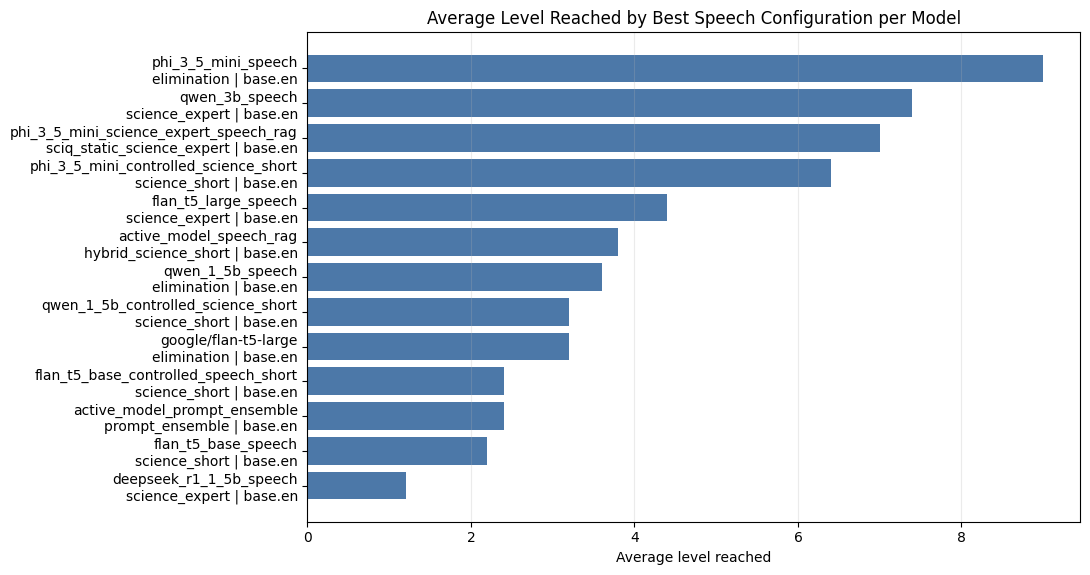

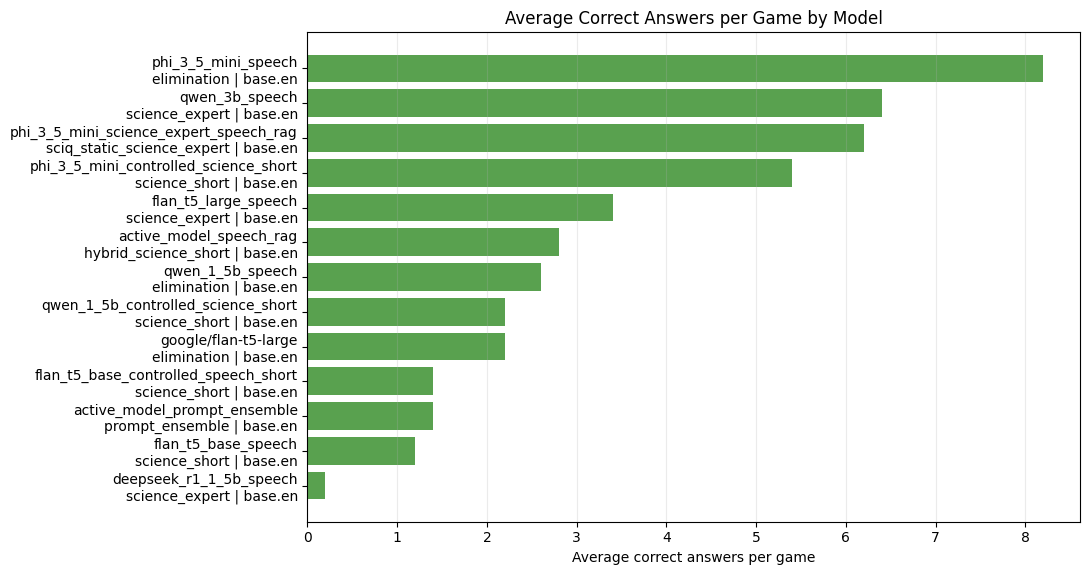

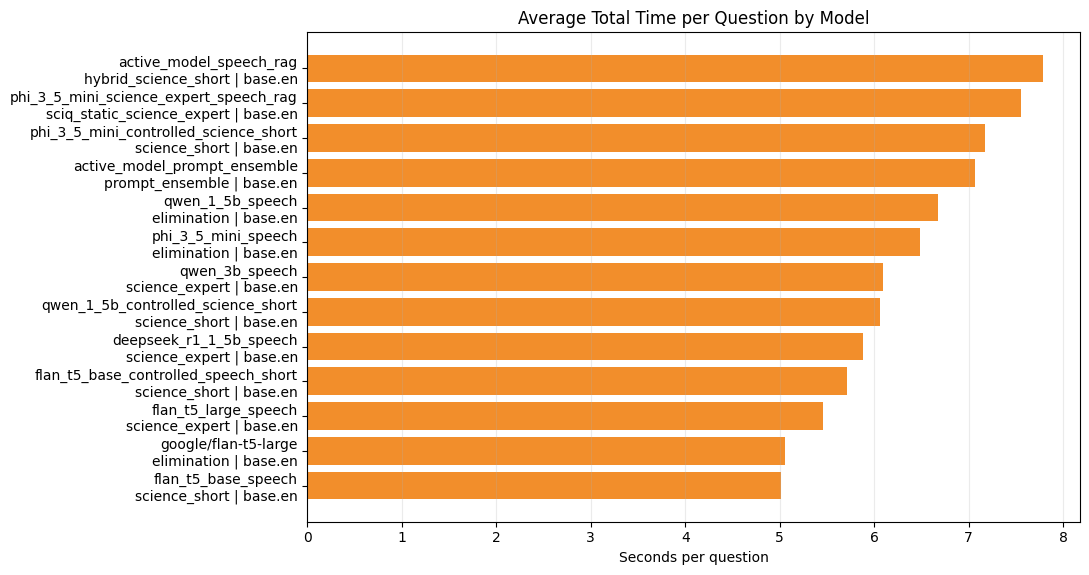

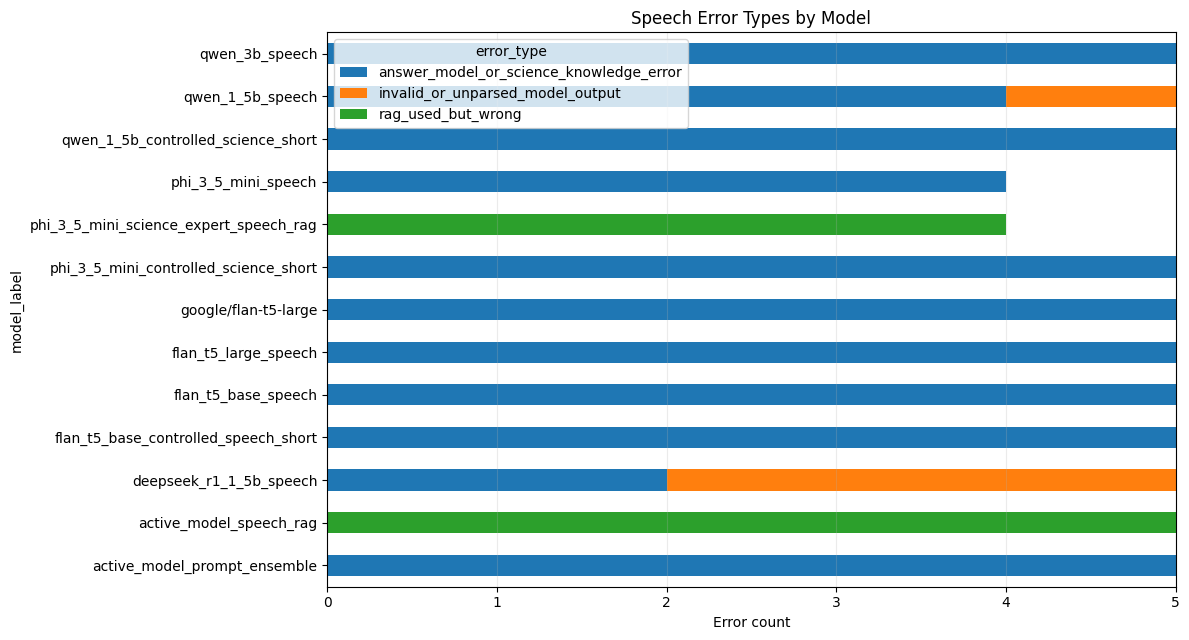

Saved clean CSV and PNG outputs in: speech_5run_comparison_outputs


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt


SPEECH_COMPARISON_EXPECTED_RUNS = 5
SPEECH_COMPARISON_MIN_TOPIC_QUESTIONS = 2
SPEECH_COMPARISON_OUTPUT_DIR = Path("speech_5run_comparison_outputs")
SPEECH_COMPARISON_OUTPUT_DIR.mkdir(exist_ok=True)

SPEECH_COMPARABLE_LOG_NAMES = [
    "df_speech_prompt_benchmark",
    "df_speech_asr_comparison",
    "df_speech_answer_model_comparison",
    "df_speech_rag",
    "df_speech_phi_rag",
    "df_speech_prompt_ensemble",
    "df_speech_controlled_final",
]

SPEECH_NAN_GUIDE = pd.DataFrame(
    [
        {
            "field_type": "RAG fields",
            "why_nan_appears": "Only RAG runs have retrieval scores, sources, and fallback reasons.",
            "what_to_do": "Compare RAG metrics only inside the RAG rows.",
        },
        {
            "field_type": "WER fields",
            "why_nan_appears": "WER needs a reference question and the jiwer package.",
            "what_to_do": "Use ASR log probability and manual examples when WER is unavailable.",
        },
        {
            "field_type": "Legacy rows",
            "why_nan_appears": "Older quick tests did not log every enhanced column.",
            "what_to_do": "Use the clean tables in this section for the final report.",
        },
    ]
)

display(SPEECH_NAN_GUIDE)


def collect_comparable_speech_logs(include_legacy_speech_results=False):
    logs = []

    for name in SPEECH_COMPARABLE_LOG_NAMES:
        value = globals().get(name)
        if isinstance(value, pd.DataFrame) and not value.empty and "correct" in value.columns:
            df_value = value.copy()
            df_value["source_table"] = name
            logs.append(df_value)

    if include_legacy_speech_results:
        value = globals().get("speech_results")
        if isinstance(value, pd.DataFrame) and not value.empty and "correct" in value.columns:
            df_value = value.copy()
            df_value["source_table"] = "speech_results_legacy"
            logs.append(df_value)

    if not logs:
        return pd.DataFrame()

    combined = pd.concat(logs, ignore_index=True, sort=False)

    if "mode" in combined.columns:
        mode_text = combined["mode"].fillna("speech").astype(str).str.lower()
        combined = combined[mode_text.eq("speech")].copy()

    return combined


def prepare_comparable_speech_logs(include_legacy_speech_results=False):
    raw_logs = collect_comparable_speech_logs(include_legacy_speech_results=include_legacy_speech_results)
    if raw_logs.empty:
        return pd.DataFrame()

    prepared = prepare_speech_question_level_analysis(raw_logs)
    if "source_table" not in prepared.columns:
        prepared["source_table"] = "unknown_source"

    for flag_column in ["correct", "valid_output", "used_fallback", "under_30_seconds", "near_timeout", "low_asr_confidence"]:
        if flag_column in prepared.columns:
            prepared[flag_column] = prepared[flag_column].fillna(False).astype(bool)

    for numeric_column in [
        "elapsed_seconds",
        "answer_elapsed_seconds",
        "question_asr_elapsed_seconds",
        "option_asr_elapsed_seconds",
        "question_wer",
        "rag_retrieval_score",
    ]:
        if numeric_column in prepared.columns:
            prepared[numeric_column] = pd.to_numeric(prepared[numeric_column], errors="coerce")

    prepared["comparison_config"] = (
        prepared["model_label"].astype(str)
        + " | "
        + prepared["prompt_type"].astype(str)
        + " | ASR="
        + prepared["asr_model"].astype(str)
    )
    prepared["comparison_run_key"] = (
        prepared["source_table"].astype(str)
        + "__"
        + prepared["model_label"].astype(str)
        + "__"
        + prepared["prompt_type"].astype(str)
        + "__"
        + prepared["asr_model"].astype(str)
        + "__run_"
        + prepared["run_id"].astype(str)
    )
    return prepared


def build_5run_model_comparison(prepared):
    if prepared.empty:
        return pd.DataFrame(), pd.DataFrame()

    run_level = prepared.groupby(
        ["source_table", "model_label", "prompt_type", "asr_model", "comparison_config", "comparison_run_key"]
    ).agg(
        level_reached=("correct", "count"),
        correct_answers=("correct", "sum"),
        final_earned_amount=("earned_amount", "max"),
        average_total_time_per_question=("elapsed_seconds", "mean"),
        max_total_time=("elapsed_seconds", "max"),
        average_answer_time=("answer_elapsed_seconds", "mean"),
        average_question_asr_time=("question_asr_elapsed_seconds", "mean"),
        average_option_asr_time=("option_asr_elapsed_seconds", "mean"),
        under_30_seconds_rate=("under_30_seconds", "mean"),
        valid_output_rate=("valid_output", "mean"),
        fallback_rate=("used_fallback", "mean"),
        near_timeout_rate=("near_timeout", "mean"),
        low_asr_confidence_count=("low_asr_confidence", "sum"),
        average_question_wer=("question_wer", "mean"),
    ).reset_index()

    config_summary = run_level.groupby(
        ["source_table", "model_label", "prompt_type", "asr_model", "comparison_config"]
    ).agg(
        runs_completed=("comparison_run_key", "nunique"),
        average_level_achieved=("level_reached", "mean"),
        best_level_achieved=("level_reached", "max"),
        average_correct_answers_in_game=("correct_answers", "mean"),
        best_correct_answers_in_game=("correct_answers", "max"),
        total_correct_answers=("correct_answers", "sum"),
        average_final_earned_amount=("final_earned_amount", "mean"),
        best_final_earned_amount=("final_earned_amount", "max"),
        average_total_time_per_question=("average_total_time_per_question", "mean"),
        max_total_time=("max_total_time", "max"),
        average_answer_time=("average_answer_time", "mean"),
        average_question_asr_time=("average_question_asr_time", "mean"),
        average_option_asr_time=("average_option_asr_time", "mean"),
        under_30_seconds_rate=("under_30_seconds_rate", "mean"),
        valid_output_rate=("valid_output_rate", "mean"),
        fallback_rate=("fallback_rate", "mean"),
        near_timeout_rate=("near_timeout_rate", "mean"),
        low_asr_confidence_count=("low_asr_confidence_count", "sum"),
        average_question_wer=("average_question_wer", "mean"),
    ).reset_index()

    config_summary["average_correct_answers_out_of_15"] = config_summary["average_correct_answers_in_game"]
    config_summary["average_game_accuracy_out_of_15"] = (
        config_summary["average_correct_answers_out_of_15"] / MAX_GAME_QUESTIONS
    )
    config_summary["needs_more_runs"] = config_summary["runs_completed"] < SPEECH_COMPARISON_EXPECTED_RUNS
    config_summary = config_summary.sort_values(
        [
            "average_level_achieved",
            "average_correct_answers_in_game",
            "under_30_seconds_rate",
            "average_total_time_per_question",
        ],
        ascending=[False, False, False, True],
    ).reset_index(drop=True)
    config_summary.insert(0, "rank", range(1, len(config_summary) + 1))

    return config_summary, run_level


def choose_best_config_per_model(config_summary):
    if config_summary.empty:
        return pd.DataFrame()

    return (
        config_summary.sort_values(
            [
                "model_label",
                "average_level_achieved",
                "average_correct_answers_in_game",
                "under_30_seconds_rate",
                "average_total_time_per_question",
            ],
            ascending=[True, False, False, False, True],
        )
        .groupby("model_label")
        .head(1)
        .sort_values(
            ["average_level_achieved", "average_correct_answers_in_game", "under_30_seconds_rate"],
            ascending=False,
        )
        .reset_index(drop=True)
    )


def filter_to_best_model_configs(prepared, best_config_per_model):
    if prepared.empty or best_config_per_model.empty:
        return pd.DataFrame()

    keys = best_config_per_model[["source_table", "model_label", "prompt_type", "asr_model"]].drop_duplicates()
    return prepared.merge(keys, on=["source_table", "model_label", "prompt_type", "asr_model"], how="inner")


def build_subject_and_error_tables(best_logs):
    if best_logs.empty:
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    subject_model_summary = best_logs.groupby(["model_label", "topic"]).agg(
        subject_questions=("correct", "count"),
        subject_correct_answers=("correct", "sum"),
        subject_correct_rate=("correct", "mean"),
        subject_errors=("correct", lambda values: (~values.astype(bool)).sum()),
        average_total_time=("elapsed_seconds", "mean"),
        average_question_wer=("question_wer", "mean"),
        low_asr_confidence_count=("low_asr_confidence", "sum"),
    ).reset_index()
    subject_model_summary["subject_error_rate"] = (
        subject_model_summary["subject_errors"] / subject_model_summary["subject_questions"].clip(lower=1)
    )

    best_model_by_subject = (
        subject_model_summary[
            subject_model_summary["subject_questions"] >= SPEECH_COMPARISON_MIN_TOPIC_QUESTIONS
        ]
        .sort_values(
            ["topic", "subject_correct_rate", "subject_correct_answers", "subject_questions", "average_total_time"],
            ascending=[True, False, False, False, True],
        )
        .groupby("topic")
        .head(1)
        .reset_index(drop=True)
        .rename(columns={"model_label": "best_model_for_subject"})
    )

    error_by_model_subject_type = (
        best_logs[best_logs["correct"] == False]
        .groupby(["model_label", "topic", "error_type"])
        .size()
        .reset_index(name="error_count")
        .sort_values(["model_label", "topic", "error_count"], ascending=[True, True, False])
    )

    weak_subjects_by_model = (
        subject_model_summary[
            subject_model_summary["subject_questions"] >= SPEECH_COMPARISON_MIN_TOPIC_QUESTIONS
        ]
        .sort_values(
            ["model_label", "subject_error_rate", "subject_errors", "subject_questions"],
            ascending=[True, False, False, False],
        )
        .groupby("model_label")
        .head(3)
        .reset_index(drop=True)
    )

    return subject_model_summary, best_model_by_subject, error_by_model_subject_type, weak_subjects_by_model


def save_barh_plot(df, label_column, value_column, title, xlabel, filename, color="#4C78A8"):
    if df.empty or value_column not in df.columns:
        return

    plot_data = df[[label_column, value_column]].dropna().sort_values(value_column)
    if plot_data.empty:
        return

    height = max(4, 0.45 * len(plot_data))
    fig, ax = plt.subplots(figsize=(11, height))
    ax.barh(plot_data[label_column].astype(str), plot_data[value_column], color=color)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(SPEECH_COMPARISON_OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()


def save_stacked_error_plot(error_by_model_subject_type, filename="speech_error_types_by_model.png"):
    if error_by_model_subject_type.empty:
        return

    error_by_model = error_by_model_subject_type.groupby(["model_label", "error_type"])["error_count"].sum().unstack(fill_value=0)
    if error_by_model.empty:
        return

    fig, ax = plt.subplots(figsize=(12, max(4, 0.5 * len(error_by_model))))
    error_by_model.plot(kind="barh", stacked=True, ax=ax)
    ax.set_title("Speech Error Types by Model")
    ax.set_xlabel("Error count")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(SPEECH_COMPARISON_OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()


speech_comparable_logs = prepare_comparable_speech_logs(include_legacy_speech_results=False)

if speech_comparable_logs.empty:
    print("No comparable enhanced speech logs found yet. Run the model/RAG/comparison cells above first.")
else:
    speech_5run_model_comparison, speech_5run_run_level = build_5run_model_comparison(speech_comparable_logs)
    speech_best_config_per_model = choose_best_config_per_model(speech_5run_model_comparison)
    speech_best_model_logs = filter_to_best_model_configs(speech_comparable_logs, speech_best_config_per_model)

    (
        speech_subject_model_summary,
        speech_best_model_by_subject,
        speech_error_by_model_subject_type,
        speech_weak_subjects_by_model,
    ) = build_subject_and_error_tables(speech_best_model_logs)

    speech_5run_model_comparison.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_5run_all_model_config_summary.csv", index=False)
    speech_5run_run_level.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_5run_run_level_summary.csv", index=False)
    speech_best_config_per_model.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_5run_best_config_per_model.csv", index=False)
    speech_subject_model_summary.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_5run_subject_model_summary.csv", index=False)
    speech_best_model_by_subject.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_5run_best_model_by_subject.csv", index=False)
    speech_error_by_model_subject_type.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_5run_error_by_model_subject_type.csv", index=False)
    speech_weak_subjects_by_model.to_csv(SPEECH_COMPARISON_OUTPUT_DIR / "speech_5run_weak_subjects_by_model.csv", index=False)

    print("Clean 5-run model/configuration comparison")
    display(speech_5run_model_comparison)

    print("Best observed configuration per model")
    display(speech_best_config_per_model)

    print("Best model by subject")
    display(speech_best_model_by_subject)

    print("Weakest subjects for each model")
    display(speech_weak_subjects_by_model)

    print("Error analysis by model, subject, and error type")
    display(speech_error_by_model_subject_type)

    speech_best_config_per_model["model_config_label"] = (
        speech_best_config_per_model["model_label"].astype(str)
        + "\n"
        + speech_best_config_per_model["prompt_type"].astype(str)
        + " | "
        + speech_best_config_per_model["asr_model"].astype(str)
    )

    save_barh_plot(
        speech_best_config_per_model,
        "model_config_label",
        "average_level_achieved",
        "Average Level Reached by Best Speech Configuration per Model",
        "Average level reached",
        "speech_average_level_by_model.png",
    )

    save_barh_plot(
        speech_best_config_per_model,
        "model_config_label",
        "average_correct_answers_in_game",
        "Average Correct Answers per Game by Model",
        "Average correct answers per game",
        "speech_average_correct_answers_by_model.png",
        color="#59A14F",
    )

    save_barh_plot(
        speech_best_config_per_model,
        "model_config_label",
        "average_total_time_per_question",
        "Average Total Time per Question by Model",
        "Seconds per question",
        "speech_average_time_by_model.png",
        color="#F28E2B",
    )

    # Heatmap charts were intentionally removed from the clean 5-run section.
    # The CSV topic tables are still saved above, but the final report uses the
    # model/configuration tables and simple bar charts instead of topic heatmaps.

    save_stacked_error_plot(speech_error_by_model_subject_type)

    print("Saved clean CSV and PNG outputs in:", SPEECH_COMPARISON_OUTPUT_DIR)


## Final report: Speech Science experiments

### Aim of this section

In this section I tested the Science quiz in the speech setting. The system first receives the spoken question and spoken answer options, then transcribes the audio with Whisper, sends the transcript to a local answer model, extracts one option from A/B/C/D, and submits the answer.

This means the speech result is not only testing the language model. It is testing the full pipeline:

1. speech transcription,
2. answer-model reasoning,
3. valid option extraction,
4. response time under the game limit.

Because of this, a wrong answer can happen because of ASR errors, weak science reasoning, invalid model output, or RAG using the wrong context.

---

### Accuracy definition used in the report

For the final report I use the full-game denominator:

```text
game accuracy = average correct answers / 15
```

I do not use only the accuracy over the questions that the model reached, because that can be misleading. For example, if a model answers only 2 questions and gets both correct, the seen-question accuracy is 1.0, but the game performance is only 2/15. Therefore, the main metric in this report is average correct answers out of 15.

---

## Main results

### Best overall speech Science system

The best overall configuration in the clean 5-run comparison was:

```text
Phi-3.5-mini + elimination prompt + Whisper base.en
```

This configuration achieved:

- average level achieved: **9.0**
- best level achieved: **15**
- average correct answers: **8.2 / 15**
- game accuracy out of 15: **0.547**
- valid output rate: **1.0**
- under-30-second rate: **1.0**
- near-timeout rate: **0.0**
- low ASR confidence count: **0**

This was the strongest final speech Science result. The model survived much longer than the other configurations and reached the full 15-question game in its best run.

The top configurations in the clean table were:

| Rank | Configuration | Average level | Best level | Average correct / 15 | Game accuracy |
|---:|---|---:|---:|---:|---:|
| 1 | Phi-3.5-mini + elimination + base.en | 9.0 | 15 | 8.2 / 15 | 0.547 |
| 2 | Qwen 3B + science_expert + base.en | 7.4 | 15 | 6.4 / 15 | 0.427 |
| 3 | Phi-3.5-mini + SciQ RAG + science_expert + base.en | 7.0 | 15 | 6.2 / 15 | 0.413 |
| 4 | Phi-3.5-mini controlled science_short + base.en | 6.4 | 15 | 5.4 / 15 | 0.360 |
| 5 | Phi-3.5-mini + few_shot_science + base.en | 6.2 | 9 | 5.2 / 15 | 0.347 |

This shows that Phi-3.5-mini was the strongest model family overall. Qwen 3B was the closest competitor, especially with the `science_expert` prompt.

---

## Prompt comparison

The best prompt was not the same for every model.

For Phi-3.5-mini, the best prompt in the final clean comparison was:

```text
elimination
```

This performed better than the other Phi prompt settings:

| Phi configuration | Average level | Best level | Average correct / 15 |
|---|---:|---:|---:|
| Phi-3.5-mini + elimination | 9.0 | 15 | 8.2 |
| Phi-3.5-mini + few_shot_science | 6.2 | 9 | 5.2 |
| Phi-3.5-mini + chain_of_thought | 6.0 | 12 | 5.0 |
| Phi-3.5-mini + science_short | 6.0 | 8 | 5.0 |
| Phi-3.5-mini + science_expert | 4.6 | 9 | 3.6 |
| Phi-3.5-mini + baseline | 4.6 | 7 | 3.6 |

This means that the best Science speech prompt was not the one I originally expected. The `science_expert` prompt worked well for Qwen 3B, but for Phi-3.5-mini the elimination prompt was clearly stronger.

My interpretation is that the elimination prompt helped Phi compare the answer options more carefully. This is useful in the Science quiz because many questions are multiple-choice factual questions where the wrong options can look close to the correct answer.

---

## ASR comparison

The ASR comparison changed the Whisper model while keeping the answer model/prompt setting fixed. In that isolated ASR comparison, all ASR models stayed under the 30-second limit, but the average correct answers were still low because the answer model used in that block was not the strongest final model.

The ASR comparison results were:

| ASR model | Average level | Best level | Average correct / 15 | Game accuracy |
|---|---:|---:|---:|---:|
| `tiny.en` | 2.4 | 7 | 0.65 / 15 | 0.043 |
| `base.en` | 2.2 | 5 | 0.65 / 15 | 0.043 |
| `small.en` | 1.4 | 3 | 0.19 / 15 | 0.012 |

Even though `tiny.en` was slightly higher in this isolated table, I did not choose it as the final ASR model. The best final systems were tested with `base.en`, and `base.en` gave a good balance between speed and transcript quality in the main model-comparison runs.

---

## RAG interpretation

### Original exploratory RAG

The first RAG block used the generic label:

```text
active_model_speech_rag
```

This means it was exploratory. It tested RAG with the active model in the notebook, but it was not the fairest comparison against the best final model.

In the clean table, the best original RAG row was:

```text
active_model_speech_rag + hybrid_science_short + base.en
```

This reached:

- average level: **3.8**
- best level: **8**
- average correct answers: **2.8 / 15**
- game accuracy: **0.187**

The best reproducible static-only exploratory RAG row was:

```text
active_model_speech_rag + sciq_static_science_short + base.en
```

This reached:

- average level: **3.6**
- best level: **8**
- average correct answers: **2.6 / 15**
- game accuracy: **0.173**

These results show that the original RAG setup was useful to test the idea, but it was much weaker than the final Phi-based speech systems.

### Fair Phi RAG test

The fairer RAG comparison was the added Phi RAG run:

```text
Phi-3.5-mini + science_expert + SciQ static RAG + Whisper base.en
```

This is the proper RAG model check because it explicitly reloads:

```text
microsoft/Phi-3.5-mini-instruct
```

and uses the reproducible SciQ static retrieval source.

In the clean comparison, the Phi RAG result was:

- average level achieved: **7.0**
- best level achieved: **15**
- average correct answers: **6.2 / 15**
- game accuracy out of 15: **0.413**
- valid output rate: **1.0**
- under-30-second rate: **1.0**
- near-timeout rate: **0.0**

This is a strong result. It was the third-best configuration overall in the clean 5-run comparison and it reached all 15 questions in its best run.

However, it still did not beat the best non-RAG configuration:

```text
Phi-3.5-mini + elimination + base.en
```

The best non-RAG Phi system achieved **8.2 / 15**, while Phi RAG achieved **6.2 / 15**. So in this notebook, RAG improved compared with the older exploratory RAG rows, but it did not improve over the strongest final non-RAG model.

---

## Error analysis

The error analysis shows that the main problem was not timing or invalid outputs.

For the strongest systems:

- valid output rate was **1.0**
- under-30-second rate was **1.0**
- near-timeout rate was **0.0**
- low ASR confidence count was **0**

This means the speech pipeline was fast enough and the models usually produced valid A/B/C/D answers.

For the Phi RAG run, the remaining errors were labelled as:

```text
rag_used_but_wrong
```

The error table showed these Phi RAG mistakes:

| Topic | Error type | Error count |
|---|---|---:|
| General science | `rag_used_but_wrong` | 2 |
| Earth & environment | `rag_used_but_wrong` | 1 |
| Scientific method & measurement | `rag_used_but_wrong` | 1 |

This means that RAG was actually used, but the model still selected the wrong answer. So the issue was not that retrieval failed completely. The issue was that the retrieved context did not always lead to the correct option, or the model did not use the context correctly.

The weakest topic areas for Phi RAG were:

| Topic | Correct answers | Correct rate | Error rate |
|---|---:|---:|---:|
| Scientific method & measurement | 2 / 3 | 0.667 | 0.333 |
| Earth & environment | 4 / 5 | 0.800 | 0.200 |
| General science | 14 / 16 | 0.875 | 0.125 |

These are still good topic-level results, but they show that RAG was not perfect. Also, because some topics contain only a small number of questions, the topic-level analysis should be interpreted carefully.

---

## Topic analysis

The topic analysis showed that different models were strongest in different science areas.

The best observed model by topic was:

| Topic | Best observed model | Correct rate |
|---|---|---:|
| Biology & medicine | Phi-3.5-mini controlled science_short | 1.0 |
| Chemistry & materials | Phi-3.5-mini controlled science_short | 1.0 |
| Earth & environment | Qwen 3B | 1.0 |
| General science | FLAN-T5-large | 1.0 |
| People & history of science | Qwen 1.5B | 0.5 |
| Physics & astronomy | Phi-3.5-mini | 1.0 |
| Scientific method & measurement | Phi-3.5-mini | 1.0 |

This suggests that a topic-aware system could maybe improve the result in the future. For example, Phi was very strong overall, but Qwen 3B also performed very well in some areas. A future ensemble could choose the answer model depending on the detected science topic.

---

## Final conclusion

The best final Science speech system in this notebook was:

```text
Phi-3.5-mini + elimination prompt + Whisper base.en
```

It achieved an average of **8.2 correct answers out of 15**, with an average level of **9.0** and a best run of **15 questions**. This was the strongest result in the clean 5-run comparison.

The Phi RAG experiment was also strong. It used:

```text
Phi-3.5-mini + science_expert + SciQ static RAG + Whisper base.en
```

and achieved **6.2 correct answers out of 15**, with a best run of **15 questions**. This shows that RAG can work in the speech Science setting, especially when it is combined with the stronger Phi model. However, it did not beat the best non-RAG Phi configuration.

Therefore, for the final system, I would choose the non-RAG Phi-3.5-mini with the elimination prompt. I would report Phi RAG as a useful extension, but not as the final best model.

The main conclusion is that the strongest improvement came from using a better answer model and a better prompt, rather than just adding retrieval. RAG helped when the retrieved SciQ context was relevant, but it could still produce `rag_used_but_wrong` errors. For future work, I would improve the retrieval filtering and also test RAG with the elimination prompt, because elimination was the best prompt for Phi in the clean final comparison.
